# M19 · Hessienne, conditionnement et convergence — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m19_hessienne_convergence/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M19.1 à M19.9, M19.14, M19.15 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M19.19 | La hessienne par différences centrées · `numerical_hessian` | 🔨 | ★★ | 25 |
|  | M19.20 | Le pas critique d'une matrice symétrique définie positive, et les itérés de Richardson · `critical_step_size, richardson_iterates` | 🔨 | ★★ | 25 |
|  | M19.21 | Une récurrence linéaire d'ordre d · `linear_recurrence` | 🔨 | ★ | 15 |
| B | M19.22 | `scipy.sparse.linalg.cg` : le gradient conjugué contre Richardson | 📦 | ★ | 15 |
|  | M19.23 | Prédire le nombre d'itérations de Richardson selon ω, puis vérifier | 🔮 | ★ | 10 |
|  | M19.24 | Le nombre d'itérations contre le conditionnement : une droite en échelle logarithmique | 🔬 | ★★ | 20 |
| C | M19.25 | Les itérés de Richardson sur les lignes de niveau d'une forme quadratique | 🎨 | ★ | 20 |
|  | M19.26 | Chasse à l'erreur : un pas réglé sur λmin, une hessienne non symétrique, le module d'une racine complexe | 🐛 | ★ | 15 |
|  | M19.27 | Un critère d'arrêt : le résidu relatif ‖b − A x‖/‖b‖ et un nombre maximal d'itérations | 🛠️ | ★ | 15 |
|  | M19.28 | Défi : le schéma saute-mouton d'un oscillateur, x_{k+1} = (2 − h²Ω²) x_k − x_{k−1}, borné si et seulement si hΩ < 2 | 🏆 | ★★★ | 30 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : une hessienne et Taylor d'ordre 2, des points critiques en dimension 3, une itération linéaire, Richardson à la main, le meilleur pas et le nombre d'itérations, deux récurrences d'ordre 2, un gradient estimé sur un échantillon, deux projections, et deux ponts.
- Écrire les quatre fonctions de `mymath/iterative.py` (`numerical_hessian`, `critical_step_size`, `richardson_iterates`, `linear_recurrence`) et les tester.
- Comparer le gradient conjugué de SciPy à Richardson, prédire puis compter des itérations, mesurer leur croissance avec le conditionnement, dessiner des itérés sur des lignes de niveau, corriger trois erreurs classiques, écrire un critère d'arrêt, et relever un défi : la stabilité du schéma saute-mouton.

**Rappel express.** Hessienne $H_{ij} = \frac{\partial^2 f}{\partial x_i\partial x_j}$, symétrique ; $f(\mathbf{x} + \mathbf{h}) \approx f(\mathbf{x}) + \nabla f^\top\mathbf{h} + \frac12\mathbf{h}^\top\mathbf{H}\mathbf{h}$ ; par différences centrées, $h \approx 10^{-4}$. En un point critique : valeurs propres toutes $> 0$, minimum ; toutes $< 0$, maximum ; des deux signes, selle. $\mathbf{x}_{k+1} = \mathbf{M}\mathbf{x}_k + \mathbf{c}$, $\mathbf{M}$ symétrique : convergence depuis tout départ si et seulement si $\rho = \max_i\lvert\lambda_i\rvert < 1$ ; $k \ge \frac{d\ln 10}{-\ln\rho}$ pour gagner $d$ décimales. Richardson $\mathbf{x} \leftarrow \mathbf{x} + \omega(\mathbf{b} - \mathbf{A}\mathbf{x})$ : $0 < \omega < \frac{2}{\lambda_{\max}}$, $\rho(\omega) = \max(\lvert 1 - \omega\lambda_{\min}\rvert, \lvert 1 - \omega\lambda_{\max}\rvert)$, meilleur pas $\frac{2}{\lambda_{\min} + \lambda_{\max}}$ de facteur $\frac{\kappa - 1}{\kappa + 1}$, environ $1{,}15\,\kappa\,d$ itérations ; gradient conjugué : de l'ordre de $\sqrt\kappa$, au plus $n$. Récurrence $u_{k+2} = p\,u_{k+1} - q\,u_k$ : racines de $r^2 - pr + q$, complexes de module $\sqrt q$ si $p^2 < 4q$ ; $u_k \to 0$ depuis tout départ si et seulement si $\lvert q\rvert < 1$ et $\lvert p\rvert < 1 + q$.

## Partie 0 · Vérifier tes exercices papier (✏️ M19.1 à M19.9, 🔗 M19.14 et M19.15)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question (une valeur exacte se tape aussi comme un calcul, `1/8`) ;
- une liste `[0.2, -1]`, ou une liste de listes ;
- une matrice comme la liste de ses **lignes** : `[[1, 0], [-2, 3]]` ; un nombre décimal s'y écrit avec un point, `[[0.25, 1], [0, 2]]` ;
- une fraction irréductible entre guillemets, `"3/7"`, quand la question le dit ;
- une lettre entre guillemets pour un choix, `"D"` ; `True` ou `False` pour un vrai ou faux.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly (SymPy, fractions) from the statements
import math
from fractions import Fraction
from itertools import product

import numpy as np
import sympy

R = sympy.Rational


def rows(M):
    """A SymPy matrix as the list of its rows (Python ints, floats for the other numbers)."""
    return [[int(v) if v.is_Integer else float(v) for v in M.row(i)] for i in range(M.rows)]


def flat(values):
    """SymPy numbers (a row, a column, a list) as a flat list (Python ints, floats for the other numbers)."""
    return [int(v) if sympy.sympify(v).is_Integer else float(v) for v in values]


def steps_to_gain(rho, d=6):
    """The smallest k with rho^k ≤ 10^(−d), for an exact 0 < rho < 1 (computed with 50 digits)."""
    k = sympy.N(d * sympy.log(10) / -sympy.log(rho), 50)
    assert abs(k - sympy.floor(k)) > 1e-30                   # never an integer: the rounding up is safe
    return int(sympy.ceiling(k))


x_, y_, z_ = sympy.symbols("x y z")                                                              # M19.1
V_1 = (x_, y_, z_)
F_1 = x_ ** 2 * z_ + y_ * z_ ** 2 - 3 * x_ * y_ + sympy.exp(x_ - y_)
P_1 = {x_: 1, y_: 1, z_: 2}
GRAD_1 = sympy.Matrix([sympy.diff(F_1, v) for v in V_1]).subs(P_1)
HESS_1 = sympy.hessian(F_1, V_1).subs(P_1)
H_1 = sympy.Matrix([R(1, 10), R(-2, 10), R(1, 10)])                  # (1.1, 0.8, 2.1) − p
TAYLOR1_1 = F_1.subs(P_1) + (GRAD_1.T * H_1)[0]
TAYLOR2_1 = TAYLOR1_1 + (H_1.T * HESS_1 * H_1)[0] / 2
TRUE_1 = F_1.subs({x_: R(11, 10), y_: R(8, 10), z_: R(21, 10)})
U_1 = sympy.Matrix([2, -1, 2]) / 3
CURVATURE_1 = (U_1.T * HESS_1 * U_1)[0]
F_2 = x_ ** 3 + 3 * x_ * y_ ** 2 - 15 * x_ - 12 * y_ + z_ ** 2 - 2 * z_                           # M19.2
CRIT_2 = sorted([int(s[v]) for v in V_1] for s in sympy.solve([sympy.diff(F_2, v) for v in V_1], V_1, dict=True)
                if all(s[v].is_real for v in V_1))
HESS_2 = sympy.hessian(F_2, V_1)
EIGEN_2 = {tuple(p): sorted(int(v) for v, m in HESS_2.subs(dict(zip(V_1, p))).eigenvals().items() for _ in range(m))
           for p in CRIT_2}
M_3 = sympy.Matrix([[R(5, 10), R(2, 10)], [R(2, 10), R(2, 10)]])                                 # M19.3
C_3 = sympy.Matrix([R(16, 10), R(8, 10)])
STAR_3 = (sympy.eye(2) - M_3).solve(C_3)
ZERO_3, X0_3 = sympy.zeros(2, 1), sympy.Matrix([4, 7])
BASIS_3 = sympy.Matrix([[2, 1], [1, -2]])                          # the columns q1 = (2, 1) and q2 = (1, −2)


def iterate_3(x0, k):
    """x_k of x ← M x + c from x0, exactly."""
    x = x0
    for _ in range(k):
        x = M_3 * x + C_3
    return x


EIGEN_3 = [(M_3 * BASIS_3[:, j])[0] / BASIS_3[0, j] for j in range(2)]
assert all(M_3 * BASIS_3[:, j] == EIGEN_3[j] * BASIS_3[:, j] for j in range(2))
STEPS_3 = steps_to_gain(max(abs(v) for v in EIGEN_3), 3)
E0_G_3 = sympy.Matrix([5, 0]) - STAR_3
G_3 = bool(M_3 * E0_G_3 == EIGEN_3[1] * E0_G_3)                  # the start error is an eigenvector of 0.1
A_4, B_4 = sympy.Matrix([[5, 3], [3, 5]]), sympy.Matrix([2, 6])                                   # M19.4
STAR_4, OMEGA_4 = A_4.solve(B_4), R(8, 100)
RICH_4, x_4 = [], sympy.zeros(2, 1)
for _ in range(3):
    x_4 = x_4 + OMEGA_4 * (B_4 - A_4 * x_4)
    RICH_4.append(x_4)
EIGEN_4 = sorted((int(v) for v in A_4.eigenvals()), reverse=True)
G_4 = max((1 - R(3, 10) * v for v in EIGEN_4), key=abs)
SMALL_4 = min((1 - R(3, 10) * v for v in EIGEN_4), key=abs)
E0_H_4 = sympy.Matrix([1, -1])
H_4 = bool(A_4 * E0_H_4 == 2 * E0_H_4 and abs(1 - R(3, 10) * 2) < 1)   # an eigenvector of 2: the factor 0.4
A_5 = sympy.Matrix([[7, 6, 0], [6, 7, 0], [0, 0, 7]])                                              # M19.5
EIGEN_5 = sorted(int(v) for v, m in A_5.eigenvals().items() for _ in range(m))
LMIN_5, LMAX_5 = sympy.Integer(EIGEN_5[0]), sympy.Integer(EIGEN_5[-1])
BEST_5 = 2 / (LMIN_5 + LMAX_5)
RHO_5 = (LMAX_5 / LMIN_5 - 1) / (LMAX_5 / LMIN_5 + 1)
assert RHO_5 == max(abs(1 - BEST_5 * v) for v in EIGEN_5)
PRUDENT_5 = max(abs(1 - v / LMAX_5) for v in EIGEN_5)
r_ = sympy.Symbol("r")                                                                             # M19.6
P_6, Q_6 = R(7, 10), R(1, 10)
ROOTS_6 = sorted(sympy.solve(r_ ** 2 - P_6 * r_ + Q_6, r_), reverse=True)
alpha_, beta_ = sympy.symbols("alpha beta")
COEFS_6 = [v for v in sympy.solve([alpha_ + beta_ - 3, alpha_ * ROOTS_6[0] + beta_ * ROOTS_6[1] - R(12, 10)],
                                  [alpha_, beta_], dict=True)[0].values()]
U_6, PLUS_6 = [R(3), R(12, 10)], [R(3), R(12, 10)]
for _ in range(9):
    U_6.append(P_6 * U_6[-1] - Q_6 * U_6[-2])
    PLUS_6.append(P_6 * PLUS_6[-1] + Q_6 * PLUS_6[-2])              # the sign of q forgotten
assert U_6[10] == 2 * R(1, 2) ** 10 + R(1, 5) ** 10
ROOTS_V_6 = sorted(sympy.solve(r_ ** 2 - R(3, 2) * r_ - 1, r_), reverse=True)
V1_6 = 2 * min(ROOTS_V_6)                       # v_k = 2 (−0.5)^k: the coefficient of 2^k is zero
P_7, Q_7 = R(5, 10), R(4225, 10000)                                                                  # M19.7
DELTA_7 = P_7 ** 2 - 4 * Q_7
RE_7, IM_7 = P_7 / 2, sympy.sqrt(-DELTA_7) / 2
MODULUS_7 = sympy.sqrt(RE_7 ** 2 + IM_7 ** 2)
assert MODULUS_7 == sympy.sqrt(Q_7)
THETA_7 = sympy.acos(P_7 / (2 * MODULUS_7))
U_7, PLUS_7 = [R(1), R(25, 100)], [R(1), R(25, 100)]
for _ in range(4):
    U_7.append(P_7 * U_7[-1] - Q_7 * U_7[-2])
    PLUS_7.append(P_7 * PLUS_7[-1] + Q_7 * PLUS_7[-2])
A_cos_, B_sin_ = sympy.symbols("A B")
AB_7 = list(sympy.solve([A_cos_ - U_7[0], MODULUS_7 * (A_cos_ * sympy.cos(THETA_7) + B_sin_ * sympy.sin(THETA_7))
                         - U_7[1]], [A_cos_, B_sin_], dict=True)[0].values())
STEPS_7 = next(k for k in range(1, 100) if MODULUS_7 ** k < R(1, 1000))
I_8, U_8, A0_8 = [1, 2, 2, 3], [2, 3, 5, 7], 2                                                     # M19.8
RESIDUALS_8 = [A0_8 * i - u for i, u in zip(I_8, U_8)]
G_8 = [2 * i * res for i, res in zip(I_8, RESIDUALS_8)]
FPRIME_8 = R(sum(G_8), 4)
SIGMA2_8 = sum((g - FPRIME_8) ** 2 for g in G_8) / 4
B_MIN_8 = next(b for b in range(1, 1000) if SIGMA2_8 / b <= R(1, 4))      # σ/√B ≤ 0.5
COUPLES_8 = [R(g + h, 2) for g, h in product(G_8, repeat=2)]                  # 16 ordered draws with replacement
POSITIVE_8 = R(sum(bool(m > 0) for m in COUPLES_8), 16)
NONNEGATIVE_8 = R(sum(bool(m >= 0) for m in COUPLES_8), 16)
PAIRS_8 = R(sum(bool(R(G_8[i] + G_8[j], 2) > 0) for i in range(4) for j in range(i, 4)), 10)
A_STAR_8 = R(sum(i * u for i, u in zip(I_8, U_8)), sum(i * i for i in I_8))
X_9 = sympy.Matrix([6, -3, 2])                                                                      # M19.9
NORM_9 = X_9.norm()
BALL_9 = X_9 * min(1, R(28, 10) / NORM_9)
BOX_9 = X_9.applyfunc(lambda v: max(min(v, 2), -2))
Y_9 = sympy.Matrix([4, -4, 4])
P_Y_9 = Y_9.applyfunc(lambda v: max(min(v, 2), -2))
F_9 = bool(sympy.Matrix.hstack(Y_9, P_Y_9).rank() == 1 and P_Y_9.dot(Y_9) > 0)
A_15 = sympy.Matrix([[16, 1], [1, R(1, 4)]])                                                       # M19.15
EIGEN_15 = sorted(A_15.eigenvals(), key=lambda v: float(v), reverse=True)
KAPPA_15 = EIGEN_15[0] / EIGEN_15[1]
SQRT_D_15 = sympy.diag(*[sympy.sqrt(A_15[i, i]) for i in range(2)])
TILDE_15 = SQRT_D_15.inv() * A_15 * SQRT_D_15.inv()
TILDE_EIGEN_15 = sorted(TILDE_15.eigenvals(), key=lambda v: float(v))
KAPPA_TILDE_15 = TILDE_EIGEN_15[-1] / TILDE_EIGEN_15[0]
STEPS_15 = [steps_to_gain((KAPPA_15 - 1) / (KAPPA_15 + 1)), steps_to_gain((KAPPA_TILDE_15 - 1) / (KAPPA_TILDE_15 + 1))]
X_15 = sympy.Matrix([R(1, 2), 2])

**Ex M19.1 — La hessienne d'une fonction de trois variables, et son développement de Taylor d'ordre 2**

In [3]:
wbm.record("M19.1a", flat(GRAD_1), mistakes={"∂(e^(x − y))/∂y = −e^(x − y) : la dérivée par rapport à y amène un signe moins":
                         flat(GRAD_1 + sympy.Matrix([0, 2, 0]))})
wbm.record("M19.1b", rows(HESS_1), mistakes={"∂²(e^(x − y))/∂x∂y = −e^(x − y) : la dérivée par rapport à y amène un signe moins":
                         rows(HESS_1 + sympy.Matrix([[0, 2, 0], [2, 0, 0], [0, 0, 0]]))})
wbm.record("M19.1c", float(TAYLOR1_1), decimals=6, mistakes={"Taylor d'ordre 1 part de f(p) : f(p) + ∇f(p)ᵀh": float(TAYLOR1_1 - F_1.subs(P_1))})
wbm.record("M19.1d", float(TAYLOR2_1), decimals=6, mistakes={"le terme d'ordre 2 est ½ hᵀHh : n'oublie pas le ½": float(2 * TAYLOR2_1 - TAYLOR1_1)})
wbm.record("M19.1e", float(TRUE_1), decimals=3, mistakes={"la vraie valeur de f, pas une approximation de Taylor : calcule f(1,1 ; 0,8 ; 2,1)":
                         float(TAYLOR2_1)})
wbm.record("M19.1f", int(CURVATURE_1), mistakes={"u est unitaire, u = (2, −1, 2)/3 : la courbure est uᵀHu, le facteur 1/9 compris":
                         int(9 * CURVATURE_1)})
wbm.record("M19.1g", int(HESS_1[:2, :2].det()), mistakes={"le déterminant d'un bloc 2 × 2 est ad − bc, avec ici b = c = −4":
                         int(HESS_1[0, 0] * HESS_1[1, 1] + HESS_1[0, 1] ** 2)})
wbm.record("M19.1h", bool(np.all(np.linalg.eigvalsh(np.array(HESS_1, dtype=float)) > 0)), mistakes={"un mineur principal négatif suffit à exclure « définie positive » (critère de Sylvester, "
                     "M12c §7) : une diagonale positive ne suffit pas": True})

WBM_ANSWER {"decimals": 0, "element_hashes": ["a4bc7b3d8a56b9ac1a41c467b3d00ef3a5ecdf72a593ed0f7667ee304c20e0bf", "f4945e28967bad9450529e36844db1f4c2b403ad2f1e91e2a4812f21303a1d0b", "be15cb38cffb2ffef9a64749862eb3c3a754251e61c608fbbd7c21cb68bf39c3"], "hash": "214b7fbfbf2aa2529574c09cd189b364d6e9b081e0d985856ac2d22dc59388d4", "id": "M19.1a", "integer": true, "kind": "array", "mistakes": {"7baac2a60057767d5b64dec9f832442c99a8f6e27e20a9c1f338dce062885a41": "∂(e^(x − y))/∂y = −e^(x − y) : la dérivée par rapport à y amène un signe moins"}, "shape": [3]}
📝 Ex M19.1a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["30882b720d013a8d026d894eb1d8c5a479b1cd57b28609dcee05ac2d92afebe8", "2fe6ec8827211e5e59ce30b0c01211fedc2b37e131e30e6834837ddb08f6ca2c", "e005c18019a96bfa2836f61377bb6ae0d626e1212ef82349200a876f63227a4f", "8059caca34a43c68ca672585bf5fbe82e6a87c73d1c80cd262e5953f881c6ad5", "81bb4b850bd4536e6496952046e4fc5d8deaaa172daac0fafb940f22ed79ca02", "229

**Ex M19.2 — Classer les points critiques d'une fonction de trois variables**

In [4]:
wbm.record("M19.2a", len(CRIT_2), mistakes={"x et y peuvent aussi être tous deux négatifs : (x + y)² = 9 donne deux valeurs de x + y":
                         len(CRIT_2) // 2})
wbm.record("M19.2b", CRIT_2, mistakes={"rangés par x CROISSANT : le plus petit x d'abord": CRIT_2[::-1]})
wbm.record("M19.2c", EIGEN_2[(2, 1, 1)], mistakes={"en ordre croissant": EIGEN_2[(2, 1, 1)][::-1]})
wbm.record("M19.2d", EIGEN_2[(-2, -1, 1)], mistakes={"en ordre croissant : la plus négative d'abord": EIGEN_2[(-2, -1, 1)][::-1]})
wbm.record("M19.2e", [sum(v < 0 for v in EIGEN_2[tuple(p)]) for p in CRIT_2], mistakes={"compte les valeurs propres NÉGATIVES": [sum(v > 0 for v in EIGEN_2[tuple(p)]) for p in CRIT_2]})
wbm.record("M19.2f", int(F_2.subs(dict(zip(V_1, (2, 1, 1))))))
wbm.record("M19.2g", all(v < 0 for v in EIGEN_2[(-2, -1, 1)]), mistakes={"la valeur propre de la direction z est la même en tout point, et positive : f y monte": True})

WBM_ANSWER {"hash": "7692f4dfe8ed664dfb3647d64a728f68b48100de1935597e8ceb508326330849", "id": "M19.2a", "kind": "int", "magnitude": 0, "mistakes": {"a36742513d6f18b5d95c4b80a21d2200cac2d02775104b4e152b7e78475ea42d": "x et y peuvent aussi être tous deux négatifs : (x + y)² = 9 donne deux valeurs de x + y"}, "sign": 1}
📝 Ex M19.2a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["9c1ff11ba52d56dbb3dbb999a41044c2f5e6f38a5a9b74f297d562124704b44d", "b281f33604d3c4ae26e8dbf5c162bb3b2d35528a788741b93924c065887a9135", "e845daafd46fe8d186068852d0b43aa39ae9b45cb2b75c46e679efd0fa6d2770", "7a6220ab4cab9f0895c6a77d539f1d197781e222184bafc4f03eae9f0c99e194", "3b4e3a697f589dac1359b21036618fcb973d0ab54a9ad5a43dfc9b505422e6b6", "597cc2a32d0e7ee6dca3e19823c844b1ab327ff9a8b7e10b4a6f00f9ad35642f", "d28b340092a67a65dd269f6c08b067a4aec3b9ff6a8b7a80ff6f2dafcdfcfdfc", "36112ae25142c54ead563425073b61751322316cbc648bd4fd769fe8480c17df", "de46897b8d0e87c3bbc35cd54ef1cc307efa79bffe3d9d065

**Ex M19.3 — Une itération linéaire 2 × 2 : point fixe, erreur, et convergence par les valeurs propres**

In [5]:
wbm.record("M19.3a", flat(STAR_3), decimals=6)
wbm.record("M19.3b", [flat(iterate_3(ZERO_3, 1)), flat(iterate_3(ZERO_3, 2))], decimals=6)
wbm.record("M19.3c", flat(EIGEN_3), decimals=6, mistakes={"l'ordre demandé : la valeur propre de q₁ d'abord, puis celle de q₂":
                         flat(EIGEN_3[::-1])})
wbm.record("M19.3d", flat(BASIS_3.solve(X0_3 - STAR_3)), decimals=6, mistakes={"décompose l'ÉCART x₀ − x*, pas x₀ lui-même": flat(BASIS_3.solve(X0_3))})
wbm.record("M19.3e", flat(iterate_3(X0_3, 3)), decimals=6, mistakes={"xₖ = x* + Mᵏ(x₀ − x*) : M³x₀ seul oublie le point fixe": flat(M_3 ** 3 * X0_3)})
wbm.record("M19.3f", STEPS_3, mistakes={"il faut ρᵏ ≤ 10⁻³ : arrondis k vers le haut, jamais vers le bas": STEPS_3 - 1})
wbm.record("M19.3g", G_3, mistakes={"regarde l'écart de départ x₀ − x* : de quel vecteur propre de M est-il un multiple ?": not G_3})

WBM_ANSWER {"decimals": 6, "element_coarse": [["e49c0feab3c5cd4ac8fa32e808094470076525648eadbdbeac316ff05d99e5c3"], ["23f0be0e38ec2cd290a736ffe0ff82e812fefb0ddbe90e8a9b748be458e3f18d"]], "element_coarse_any": [["c622025bf639ee13ad269cecbbf760a7fcfb362549a0807afa02c5f95f0558c0", "68994bc97bb48c8dcdc428f4cfe3570ce87a0e1012b16ad4a0c0de6011734aea", "e2d31a7fb6436b00ca7fba23da64c7f76dfd289cbb28b852412b65d452eb3435", "4bc2b190e738fb9bb55804449966153bd3483a25dc9b736c4aee08b196313ae3", "cce1e506c0b32e4312d268f073800077225ce435ae59cf90d414c2bf0bdc54a7"], ["86d1a6659d42120ce8ab0f1a512a5ab11972502bec975b7071135fa97d77e87b", "9bd0cea437b1b1ec32aa6695fb4b1cfd45105e12567604b9267e72441b552d6c", "f0f831c2ac1e297ee14f14419b21e43ab0ef590c694c445148e23a7bdb24b5ef", "e9917546df68b15a1df63a56db7cfaa06a1233becac262112b12b1263c731f6c", "53306e587a3f4549cb48bf07c539f0e6b60f84f5f5a0dd8203c501ae2935d084"]], "element_hashes": ["fb2287a2f9ed6a7a1c86a4fe61c5385a44afd52cf82e8d38c6a57ae4cb98e83a", "fb2223a5bb561d217

**Ex M19.4 — Résoudre un système 2 × 2 par l'itération de Richardson : trois pas à la main, et le pas critique**

In [6]:
wbm.record("M19.4a", flat(STAR_4), decimals=6)
wbm.record("M19.4b", [flat(x) for x in RICH_4], decimals=6, mistakes={"recalcule le résidu b − Axₖ à chaque pas, avec le nouvel itéré":
                         [flat(k * OMEGA_4 * B_4) for k in (1, 2, 3)]})
wbm.record("M19.4c", flat(B_4 - A_4 * RICH_4[2]), decimals=6, mistakes={"le résidu est b − Ax₃, pas Ax₃": flat(A_4 * RICH_4[2])})
wbm.record("M19.4d", EIGEN_4, mistakes={"en ordre décroissant": EIGEN_4[::-1]})
wbm.record("M19.4e", [float(1 - OMEGA_4 * v) for v in EIGEN_4], decimals=6, mistakes={"dans le même ordre que d) : d'abord celle qui vient de la plus grande valeur propre de A":
                         [float(1 - OMEGA_4 * v) for v in EIGEN_4[::-1]]})
wbm.record("M19.4f", float(R(2, max(EIGEN_4))), decimals=6, mistakes={"le pas critique se règle sur la PLUS GRANDE valeur propre": float(R(2, min(EIGEN_4)))})
wbm.record("M19.4g", float(G_4), decimals=6, mistakes={"la valeur propre de plus grand MODULE, pas de plus petit": float(SMALL_4),
                     "la valeur propre elle-même, avec son signe, pas son module": float(abs(G_4))})
wbm.record("M19.4h", H_4, mistakes={"regarde l'écart (1, −1) : de quelle valeur propre de A est-il un vecteur propre, et que vaut "
                     "1 − 0,3λ pour elle ?": not H_4})

WBM_ANSWER {"decimals": 6, "element_coarse": [["e92881fcbd60c57293358aad8528099c625e677edfd33b166d82a28715b51f47"], ["d35def50d5dfe15a5a331a805c46157d283d7fe4becd60192225437eef850efd"]], "element_coarse_any": [["289ac299ba36d70689c0ca4a8d39456ca90d3be15da3d4ee1af3b2399163958c", "4390eee0bd5ce6b12126cec7472a9369e8390a45f06f2da036a38f2592f5f92b", "97622f7bf78f38fc7851ae148c28a04d528e656e811f43c6ae7a81ca78c2477a", "e3f27bdf56fa8305d575b4bc1b2881fff8f961cd4bd8201ea28b67b5f443abf1"], ["269d3525b7067279500bcbb39a66af266f9332616ed46367372152753e77c7b1", "4c003c144999ca157ea7ceb3bdc7eaf21ca8ec153b28bbafa84d5aa981d0a850", "4e98e1b8011a72e88fb7c903ca0cdfd89f19f016a3f0abf18e1f9d4ced9275bb", "be93786c2fe5beef01f88413935e17376beb97448f46a64923585a147e67b759", "b8fbc8d05d38d0b8dd52df87e7b6c59279b343cd6cf84d1c6ab729bd9a496d47"]], "element_hashes": ["e0b069dfa8ad28850748895ca3cd58d553f06c7fa8915ddaef065cc1ba78761f", "358280ed32dc6c50f6507061ec8b06dbc2dc26af47b87f875247999af0fc83dd"], "hash": "0f81a9d5

**Ex M19.5 — Le meilleur pas de Richardson (énoncé), et le nombre d'itérations pour gagner six décimales**

In [7]:
wbm.record("M19.5a", EIGEN_5, mistakes={"en ordre croissant": EIGEN_5[::-1]})
wbm.record("M19.5b", str(2 / LMAX_5), kind="fraction", simplified=True,
           mistakes={"le pas critique se règle sur la PLUS GRANDE valeur propre": str(2 / LMIN_5)})
wbm.record("M19.5c", str(BEST_5), kind="fraction", simplified=True,
           mistakes={"le meilleur pas ne dépend que des deux valeurs propres EXTRÊMES": str(2 / (EIGEN_5[1] + LMAX_5))})
wbm.record("M19.5d", str(RHO_5), kind="fraction", simplified=True,
           mistakes={"κ = λmax/λmin est un quotient, pas une différence":
                         str((LMAX_5 - LMIN_5 - 1) / (LMAX_5 - LMIN_5 + 1))})
wbm.record("M19.5e", steps_to_gain(RHO_5), mistakes={"ρᵏ ≤ 10⁻⁶ : arrondis k vers le haut, jamais vers le bas": steps_to_gain(RHO_5) - 1})
wbm.record("M19.5f", str(PRUDENT_5), kind="fraction", simplified=True,
           mistakes={"le facteur est le plus grand des |1 − ωλᵢ| : regarde aussi la plus petite valeur propre":
                         str(abs(1 - EIGEN_5[1] / LMAX_5))})
wbm.record("M19.5g", steps_to_gain(PRUDENT_5), mistakes={"ρᵏ ≤ 10⁻⁶ : arrondis k vers le haut, jamais vers le bas": steps_to_gain(PRUDENT_5) - 1})
wbm.record("M19.5h", steps_to_gain(R(110 - 1, 110 + 1)), mistakes={"ρᵏ ≤ 10⁻⁶ : arrondis k vers le haut, jamais vers le bas": steps_to_gain(R(110 - 1, 110 + 1)) - 1})

WBM_ANSWER {"decimals": 0, "element_hashes": ["756556e288a187c9523a8633bbd04b45e8fb3b8ddd095d088cfea849caccb340", "757ca4561a7f53ff7bd9b92b524c47a0d7f48d1377e1cb94d51ae5939b7b3a15", "77fedf675a231e8d1c5466c292fdb7fda0a2ff08f3e7bd8bde046285f06a7899"], "hash": "46b657fb0bedc94480d89aef840407eee26b0ff7d4fd4392beff3d2ff0a35af6", "id": "M19.5a", "integer": true, "kind": "array", "mistakes": {"c9fe914a0b959289012d135f5aec4e80f37fc363f110e1fb078e3f619478f9e1": "en ordre croissant"}, "shape": [3]}
📝 Ex M19.5a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "1ba1084508647427e2c01e6db856b92d0ade088979efef35c6b1652c8418bf1e", "id": "M19.5b", "kind": "fraction", "mistakes": {"ff26123e5332bb6b8ca8fd70277e4d9dcf732e482b0369af88b5ae7f33e4c983": "le pas critique se règle sur la PLUS GRANDE valeur propre"}, "sign": 1, "simplified": true}
📝 Ex M19.5b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "210ca60123c00dedce4fddee2c12e72e60de75326ec8a13173c77e4cf229c8b4", "id": "M19.5c", "k

**Ex M19.6 — Une récurrence d'ordre 2 à racines réelles : terme général et convergence**

In [8]:
wbm.record("M19.6a", flat(ROOTS_6), decimals=6, mistakes={"en ordre décroissant": flat(ROOTS_6[::-1])})
wbm.record("M19.6b", flat(COEFS_6), decimals=6, mistakes={"α va avec la plus grande racine r₁": flat(COEFS_6[::-1])})
wbm.record("M19.6c", flat(U_6[2:4]), decimals=6, mistakes={"la récurrence RETRANCHE q uₖ : uₖ₊₂ = 0,7uₖ₊₁ − 0,1uₖ": flat(PLUS_6[2:4])})
wbm.record("M19.6d", float(U_6[10]), decimals=6)
wbm.record("M19.6e", flat(ROOTS_V_6), decimals=6, mistakes={"en ordre décroissant": flat(ROOTS_V_6[::-1])})
wbm.record("M19.6f", float(V1_6), decimals=6, mistakes={"vₖ tend vers 0 quand le coefficient de la racine de module > 1 est NUL : c'est "
                     "l'autre terme qui doit rester": float(2 * max(ROOTS_V_6))})
wbm.record("M19.6g", bool(abs(Q_6) < 1 and abs(P_6) < 1 + Q_6))

WBM_ANSWER {"decimals": 6, "element_coarse": [["fe30757877e164e88591a2da018ee4f1a69ea2fa4dbbdb39d03895a3dd19cd1c"], ["098fa96c09024d8bdaf8130eb57d917c0a4813d99df3d6b30a44acf1e0c063e9"]], "element_coarse_any": [["2e76185c57e8e89cbb0ee8d53ffa40bc14d88077b04bdc769d3178d3c8d02dc3", "938c4269d372a74b21091e832d16ef02fb39c2f19dc44115363ec22db5c0161d", "31a9e4373098dbb391a65e494b0f0fd47d6e5263308ed0a00b9a19a7c974443f", "8ee6375cdda10f427c85f092e14b1d3a9ddebc6db38775d8615a795cbccf09ae"], ["9a68024125cb6b62df20d947108405554e3881e33f5da5d41cd0248e1ce87554", "95a82ac9ac295c2f2ca8ace577533322af6e3e5791c8242228daac82d8702218", "c37f672c379c1fafae7858e94ebb34d0a27a91f32191edc04baf1b85a1710da6", "1b3f54b9c9713818e1a119743e4eda72ba744fa6ad92872bb110e14b117a60c8"]], "element_hashes": ["8cc65077caa3323cff20271ae8ff5813e33abfd8f71834b942a7356f5fb1e5db", "218ab82188fda0ad0e79c11dd6e81a86bdf2a0bb535813e223796658980179a2"], "hash": "eba33e150437f8427bd4868f5cb8c9501d5279bd4a6badd18d21f101ee6c7dd6", "id": "M1

**Ex M19.7 — Une récurrence d'ordre 2 à racines complexes : module et oscillation amortie**

In [9]:
wbm.record("M19.7a", float(DELTA_7), decimals=6, mistakes={"Δ = p² − 4q : n'oublie pas le facteur 4": float(P_7 ** 2 - Q_7)})
wbm.record("M19.7b", [float(RE_7), float(IM_7)], decimals=6, mistakes={"les racines sont p/2 ± i√(−Δ)/2 : divise aussi la partie imaginaire par 2":
                         [float(RE_7), float(2 * IM_7)]})
wbm.record("M19.7c", float(MODULUS_7), decimals=6, mistakes={"le module est √(a² + b²) = √q, pas la partie réelle": float(RE_7)})
wbm.record("M19.7d", float(THETA_7), decimals=4, mistakes={"un angle en radians, pas en degrés": math.degrees(float(THETA_7))})
wbm.record("M19.7e", flat(U_7[2:6]), decimals=6, mistakes={"la récurrence RETRANCHE q uₖ : uₖ₊₂ = p uₖ₊₁ − q uₖ": flat(PLUS_7[2:6])})
wbm.record("M19.7f", flat(AB_7), decimals=6)
wbm.record("M19.7g", STEPS_7, mistakes={"0,5ᵏ < 10⁻³ : arrondis k vers le haut, jamais vers le bas": STEPS_7 - 1})
wbm.record("M19.7h", float(2 * sympy.pi / THETA_7), decimals=2, mistakes={"une période complète est un tour, un angle de 2π, pas π": float(sympy.pi / THETA_7)})

WBM_ANSWER {"coarse_any": {"0": ["d85b238bf81175a0324e00638739d0497e8b0a39545ca2635f7f64612e9ecc96"]}, "coarser": {"1": ["5715fda2c9551d957f918445f05d3fe4c66d2c28346bf006f9af3e950bf94be5"], "2": ["a8bd41d9f5e58aebe7320ffcc001dcb02d1867c97f1c069371224bccc1de15f6"], "3": ["d1c0b841e1c85ae2cc4b4ecbbd2280d2fd119d36d941cf6bf7ac906f7fbb65fa"], "4": ["8e273d95b1e8a7f465f75ba396aa1f49f2f46d761bd38a16d0b8a7754aee5746"]}, "decimals": 6, "hash": "124ef77dc40707213c5a3a099566d4cffdd9c97fa4407cf85546dfd46cbf2c30", "hash_coarse": "7c9286c53800e7821970d58cf9aa424b2009b5f8fd057ea8073aea6305bcea5d", "id": "M19.7a", "kind": "float", "magnitude": 0, "mistakes": {"eceab0ecb7eaa2de9674f6f205f3d0258d5757efb30974649aba118d161b7a1e": "Δ = p² − 4q : n'oublie pas le facteur 4"}, "sign": -1}
📝 Ex M19.7a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"array_rounded": {"1": "a7c95f3ca8b6b07b40f2d0f528ae92b5982eed39d4207d88dc9ab2bbcaf29764"}, "decimals": 6, "element_coarse": [["0b368a232d21945bab86e0029c85

**Ex M19.8 — Une pente estimée sur B points tirés au hasard : espérance et variance de l'estimation**

In [10]:
wbm.record("M19.8a", float(FPRIME_8), decimals=6, mistakes={"F′(2) est la MOYENNE des quatre dérivées gₖ(2)": float(4 * FPRIME_8)})
wbm.record("M19.8b", flat(G_8), mistakes={"gₖ(a) = 2Iₖ(aIₖ − Uₖ) : multiplie chaque résidu aIₖ − Uₖ par 2Iₖ": flat(RESIDUALS_8)})
wbm.record("M19.8c", float(SIGMA2_8), decimals=6, mistakes={"σ² divise par N = 4, la dispersion des quatre gradients, pas par N − 1":
                         float(SIGMA2_8 * 4 / 3)})
wbm.record("M19.8d", float(SIGMA2_8 / 2), decimals=6, mistakes={"la variance d'une moyenne de B tirages indépendants est σ²/B, pas σ²/B²":
                         float(SIGMA2_8 / 4)})
wbm.record("M19.8e", math.sqrt(SIGMA2_8 / 2), decimals=4, mistakes={"l'erreur type est la RACINE de la variance": float(SIGMA2_8 / 2),
                     "l'erreur type est σ/√B : divise σ par √B, pas par B": math.sqrt(SIGMA2_8) / 2})
wbm.record("M19.8f", B_MIN_8, mistakes={"l'erreur type est σ/√B : élève au carré l'inégalité σ/√B ≤ 0,5": math.ceil(math.sqrt(SIGMA2_8) / 0.5)})
wbm.record("M19.8g", float(SIGMA2_8 / 2 * R(4 - 2, 4 - 1)), decimals=4, mistakes={"le facteur de population finie est (N − B)/(N − 1), pas son inverse":
                         float(SIGMA2_8 / 2 * R(4 - 1, 4 - 2))})
wbm.record("M19.8h", str(POSITIVE_8), kind="fraction", simplified=True,
           mistakes={"tirages AVEC remise : les 16 couples ordonnés sont équiprobables, pas les 10 paires": str(PAIRS_8),
                     "STRICTEMENT positive : une moyenne nulle ne compte pas": str(NONNEGATIVE_8)})
wbm.record("M19.8i", str(A_STAR_8), kind="fraction", simplified=True,
           mistakes={"a* annule F′ : a* = Σ IₖUₖ / Σ Iₖ², pas Σ Uₖ / Σ Iₖ": str(R(sum(U_8), sum(I_8)))})

WBM_ANSWER {"coarse_any": {"0": ["f06288e2977d4111e2332faf355db6a6c3c5134a57fe2b4d73a23b0961be9946"]}, "coarser": {"1": ["b19b5bb2f81565fae58e18fbc2f739c921fcae55f130e55d63468141db59298f"], "2": ["e193d46fe4035df2966fe97c27dca4041ba1e8f2416348630707d5e47a220407"], "3": ["729d982a01b66ed6ca352e3c4a458a80a4c39938472490f760bc1017e221327f"], "4": ["3a6e00b8841f26271aad7fc40e379ba6c4ffba89d7da7ceb9b0ae162549c87b5"]}, "decimals": 6, "hash": "209123276b356e888183801d0b96b67bd189acf82e498b908aa5f28c11de32b3", "hash_coarse": "9979f14314da447f04c75e42fb732834172a37cd016377d8931d9c6b847e63f9", "id": "M19.8a", "kind": "float", "magnitude": 0, "mistakes": {"a11d39d82b3eb8e8c198cb356d6fa97041f0d0da2de887b3ee063391c2c101a6": "F′(2) est la MOYENNE des quatre dérivées gₖ(2)"}, "sign": -1}
📝 Ex M19.8a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"decimals": 0, "element_hashes": ["27bc52e260c5b58d1369113e95b8bd69de556956a1346e5d7421ecd8eea1e2ba", "44eb4f67a3868d7249b0fa7f56928330289c78a51d8451

**Ex M19.9 — Projeter un même vecteur sur une boule et sur un pavé : deux points, deux directions**

In [11]:
wbm.record("M19.9a", int(NORM_9))
wbm.record("M19.9b", flat(BALL_9), decimals=6, mistakes={"couper chaque coordonnée à ±r projette sur le PAVÉ [−r, r]³, pas sur la boule":
                         flat(X_9.applyfunc(lambda v: max(min(v, R(28, 10)), -R(28, 10))))})
wbm.record("M19.9c", flat(BOX_9), mistakes={"sur un pavé, chaque coordonnée est coupée séparément, sans facteur commun":
                         flat(X_9 * R(2, 6))})
wbm.record("M19.9d", [float((X_9 - BALL_9).norm()), float((X_9 - BOX_9).norm())], decimals=4, mistakes={"la distance de x à sa projection est ‖x − P(x)‖, pas ‖x‖":
                         [float(NORM_9), float((X_9 - BOX_9).norm())]})
wbm.record("M19.9e", float(X_9.dot(BOX_9) / (NORM_9 * BOX_9.norm())), decimals=4)
wbm.record("M19.9f", F_9, mistakes={"compare les deux vecteurs : l'un est-il un multiple POSITIF de l'autre ?": not F_9})

WBM_ANSWER {"hash": "6ef1b1948bef8cf927a4d507ecb3bdf34356bd07004d25b100b971d02324df08", "id": "M19.9a", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M19.9a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 6, "element_coarse": [["1c9d13373911d87d74c8fe186190e1e36190ed93ea2ee3f211401dfe31d4f237"], ["b009447261341494e703a09d2ba5c72176645db9accf2aeb0d6276fac26ae1da"], ["eeb8561cb0decb898d9916d50665519b9603baba8c2b9e209bea4b54f90319cc"]], "element_coarse_any": [["619fec735a19f7432890601ed92dcf0eb165cfbe0a0a105dd2f6984ba7b1b1af", "20278faf7848fa4f0a4ff6bd50680db7ddcf9aaf13221777b93528240cd9adf6", "eaa8770bb9e936edfdea052727558d439064e6ab66f74ff7a4d7ec4522f0065f", "148cd8cd11b0f7e7c5e12bde989914434472dbfe491251e60f10fc07d5e252a1", "c114b3fd520e1bd8256c77009cf993eef7cf530104e5124abd2b3b57403ff9ab"], ["4bf17e77e253b2d651c381620fddb6dc6dbd70dc954bb4b266d6eb4211c005cf", "9ee86cfd842f2a8f041715256eba2a4e5ea896a5ef3102641841f7fb523c298c", "85529c95ae466355220254685124bd54279b51ecd81f7965a2b47

**Ex M19.14 — Pont : un pas de Richardson est un pas de descente sur ½ xᵀA x − bᵀx (énoncé, sans calcul)**

In [12]:
wbm.record("M19.14a", "B", mistakes={"le gradient de ½xᵀAx est Ax, celui de bᵀx est b : b − Ax en est l'opposé": "A",
                     "le ½ de ½xᵀAx compense le 2 de la dérivée de xᵀAx": "C"})
wbm.record("M19.14b", "C", mistakes={"la hessienne de ½xᵀAx est A : le ½ compense le 2 de la dérivée seconde": {"B", "D"}})
wbm.record("M19.14c", "A", mistakes={"le résidu b − Ax est l'OPPOSÉ du gradient : un pas de Richardson descend": "B"})
wbm.record("M19.14d", "A")
wbm.record("M19.14e", "B", mistakes={"c'est la plus GRANDE valeur propre qui limite le pas": "C",
                     "c'est le meilleur pas, pas celui au-dessus duquel la descente diverge": "D"})
wbm.record("M19.14f", "B", mistakes={"∇f = Ax − b : le résidu b − Ax en est l'opposé": "A"})
wbm.record("M19.14g", True, mistakes={"A symétrique définie positive : f est strictement convexe, et son unique point critique, où "
                     "∇f = 0, est la solution": False})

WBM_ANSWER {"hash": "3935624e2c3ad19485d68f1eff31a22e3a4db6a7e2bbd1847be7971cfc619e76", "id": "M19.14a", "kind": "str", "mistakes": {"3436d8edcf86146bcc1a691510997aca83881c6e850a18a6d4c2105a3571fdd2": "le gradient de ½xᵀAx est Ax, celui de bᵀx est b : b − Ax en est l'opposé", "bd01c7e51ba1440831b955829208b9170c24080830a4b2da12bda3347edd1f77": "le ½ de ½xᵀAx compense le 2 de la dérivée de xᵀAx"}}
📝 Ex M19.14a : réponse enregistrée (str).
WBM_ANSWER {"hash": "1eafa6c387af189edaeefb7cea1eb896cd6bb5ff192a971434776da0ed206d54", "id": "M19.14b", "kind": "str", "mistakes": {"3ae620ac5e110e2943b89b89d309892ae14e97a72b9dceac1a665590c0e9e5fe": "la hessienne de ½xᵀAx est A : le ½ compense le 2 de la dérivée seconde", "64a2e617677ff20f7c261b01b7c02ce8e2bb1f6ec6873f834859eecf5d0cc154": "la hessienne de ½xᵀAx est A : le ½ compense le 2 de la dérivée seconde"}}
📝 Ex M19.14b : réponse enregistrée (str).
WBM_ANSWER {"hash": "77bf012ab7849e01ea20e8ed14ac966ab3586539cda2a0cb8a8613dcc1cb0ae4", "id": "M19.

**Ex M19.15 — Pont : le préconditionnement diagonal, une idée commune à plusieurs méthodes de workbookIA 19**

In [13]:
wbm.record("M19.15a", flat(EIGEN_15), decimals=3, mistakes={"en ordre décroissant": flat(EIGEN_15[::-1])})
wbm.record("M19.15b", float(KAPPA_15), decimals=1)
wbm.record("M19.15c", rows(TILDE_15), decimals=6, mistakes={"ãᵢⱼ = aᵢⱼ/√(aᵢᵢaⱼⱼ) : divise par la racine des DEUX coefficients diagonaux":
                         rows(sympy.diag(*[1 / A_15[i, i] for i in range(2)]) * A_15)})
wbm.record("M19.15d", int(KAPPA_TILDE_15))
wbm.record("M19.15e", STEPS_15, mistakes={"l'ordre demandé : A d'abord, puis Ã": STEPS_15[::-1],
                     "ρ* arrondi trop tôt : garde 6 chiffres significatifs de ρ* = (κ − 1)/(κ + 1)":
                         [STEPS_15[0] - 1, STEPS_15[1]]})
wbm.record("M19.15f", flat(SQRT_D_15 * X_15), decimals=6, mistakes={"y = D^(1/2)x : multiplie chaque coordonnée par √aᵢᵢ, ne la divise pas":
                         flat(SQRT_D_15.inv() * X_15)})

WBM_ANSWER {"decimals": 3, "element_coarse": [["4847715b7e62d17f5c8f989afda0850abcff4dad2d7c99c44a105976be8e962b"], ["7d01a83f62b881646b35010854c9cc13dcc5bab8627b87a2037618e1313366a8"]], "element_coarse_any": [["cc3fce732d4b2731d566b76393a56ddbd3e77831ea77ff4652decdfb896ede96", "44c52439f40bf84726c30a24dbf3aa782e9c10aca125ef3e5e99235534ce79be"], ["0cb260eb46357796ff224fa1006c6afe1037b36f8124454da68643be8a8f4596"]], "element_hashes": ["60b466070d8d33916522b6a23c2a20a55b4f0449496f48c422b9f2d5191dada8", "bf2c8d0bef3d303a573b580e7133730d25f497e9950c8ffe8139bff7a78d9300"], "hash": "72b31a62022b036532900e1e59cfbfa3c8af1281f7a2cf0b042dea71ace7b796", "id": "M19.15a", "kind": "array", "mistakes": {"32fda0bfff64e81aae31f793796a023b79826a85a72c9e38f644340081904bef": "en ordre décroissant"}, "shape": [2]}
📝 Ex M19.15a : réponse enregistrée (array, 3 décimales).
WBM_ANSWER {"decimals": 1, "hash": "e4bdf984ce69175a8c999a68343abcf0b2de5b3260c33d55eac7368589891e5a", "hash_coarse": "c5528c0c86c0be99d60

## Partie A · Ta librairie : la hessienne numérique, le pas critique, les itérés de Richardson et les récurrences

Fiche §1, §2, §4, §5 et §6. Les quatre fonctions de `mymath/iterative.py`, leurs tests, et un usage de chacune.

In [14]:
# Tools of the notebook (parts A to C)
import math
import warnings

import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse
import scipy.sparse.linalg
import sympy
from matplotlib.contour import ContourSet

from wbm.nbtools import StopCheck, checked, drawn, filled, run_pytest_group, verdict

TEST_M19 = "tests/test_m19_iterative.py"          # the tests of mymath/iterative.py

### Ex M19.19 — La hessienne par différences centrées · `numerical_hessian` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer la hessienne d'une fonction de $n$ variables par différences centrées, choisir son pas, et classer un point critique de $\mathbb{R}^3$ par les signes de ses valeurs propres.  
**Prérequis :** fiche §1 et §2 ; M05a (le pas des différences finies) · **mymath :** `iterative.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/iterative.py`, lis la docstring du module puis celle de la fonction, remplace chaque `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. ⚠️ Le squelette n'importe rien : ajoute `import numpy as np` en tête du fichier (et `import numbers` si tu t'en sers pour reconnaître un entier). `np.linalg.eigvalsh` est permis dans `critical_step_size` seulement ; ni `np.linalg.solve`, ni `np.linalg.inv`, ni `scipy.optimize`, ni `scipy.sparse.linalg` : les tests comparent tes résultats aux leurs, et un test lit ton module. Les nombres se rendent en `float` de Python, les vecteurs et les matrices en tableaux NumPy de flottants ; ne modifie jamais les tableaux reçus.

Écris `numerical_hessian(f, x, h=1e-4)` (fiche §1), en suivant sa docstring : la hessienne $(n, n)$ de $f : \mathbb{R}^n \to \mathbb{R}$ en $\mathbf{x}$, par la dérivée seconde centrée sur la diagonale et par la formule à quatre points hors de la diagonale, toutes deux avec le pas `h` ; le résultat est **exactement** symétrique ; `ValueError` si `x` n'est pas un tableau 1-D non vide, ou si $h \le 0$ ; `x` n'est pas modifié.

**L'usage.** La cellule fournie donne $g(x, y) = \frac{x^2}{1 + y^2} + \cos(xy)$ (`g_19` pour NumPy, `G_EXPR_19` pour SymPy), le point $\mathbf{p} = (1{,}2 ;\ -0{,}5)$ (`P_19`), la fonction $s(x, y, z) = \cosh x + \cos y + xz + z^2$ (`s_19`), dont l'origine est un point critique, et les sept pas $h = 10^{-2}, 10^{-3}, \ldots, 10^{-8}$ (`STEPS_19`). Avec ta fonction, calcule :
- a) la hessienne numérique de $g$ en $\mathbf{p}$ (une matrice, 4 décimales) ;
- b) les valeurs propres de la hessienne numérique de $s$ en $\mathbf{0}$, en ordre croissant (`np.linalg.eigvalsh` ; une liste de 3 nombres, 4 décimales) ;
- c) l'indice de ce point critique, le nombre de ses valeurs propres négatives (un entier) ;
- d) sa nature : (A) minimum local ; (B) maximum local ; (C) point selle ; (D) le test ne conclut pas (une lettre entre guillemets) ;
- e) la hessienne exacte de $g$ en $\mathbf{p}$ par SymPy (`sympy.hessian`, puis `.subs` et `np.array(..., dtype=float)`), puis, pour chacun des sept pas de `STEPS_19`, le plus grand écart $\max_{ij}\lvert H^{\text{num}}_{ij} - H_{ij}\rvert$ : l'entier $k$ du meilleur pas $h = 10^{-k}$.

Dans ta copie : vérifie que $\mathbf{0}$ est un point critique de $s$, écris sa hessienne exacte et retrouve b) (un bloc $2 \times 2$, et un $-1$). Dans quelle direction $s$ descend-elle depuis $\mathbf{0}$ ? D'où viennent les grandes erreurs aux deux bouts de e) ? Pourquoi le meilleur pas d'une dérivée seconde est-il plus grand que celui d'une dérivée première (M05a) ? Combien de fois ta fonction évalue-t-elle $f$ pour $n = 3$, et combien d'évaluations faut-il au mieux (fiche §1) ?

In [15]:
x_19, y_19 = sympy.symbols("x y")
G_EXPR_19 = x_19 ** 2 / (1 + y_19 ** 2) + sympy.cos(x_19 * y_19)      # g, for SymPy


def g_19(v):
    """g(x, y) = x² / (1 + y²) + cos(x y), for v = (x, y) (NumPy)."""
    x, y = v
    return x ** 2 / (1 + y ** 2) + np.cos(x * y)


def s_19(v):
    """s(x, y, z) = cosh x + cos y + x z + z², for v = (x, y, z): the origin is a critical point."""
    x, y, z = v
    return np.cosh(x) + np.cos(y) + x * z + z ** 2


P_19 = np.array([1.2, -0.5])                     # the point of a) and e)
STEPS_19 = [10.0 ** -k for k in range(2, 9)]     # h = 1e-2, 1e-3, ..., 1e-8

In [16]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [17]:
run_pytest_group(TEST_M19, "numerical_hessian or module_uses", impl="ref")

pytest: 17 réussi(s), 44 non sélectionné(s) en 0,34 s


**L'usage** : la hessienne d'une fonction en un point, un point critique de $\mathbb{R}^3$, et le choix du pas.

In [18]:
numerical_hessian = mymath.iterative.numerical_hessian
answer_M19_19a = numerical_hessian(g_19, P_19).tolist()
values_19 = np.linalg.eigvalsh(numerical_hessian(s_19, np.zeros(3)))
answer_M19_19b = values_19.tolist()
answer_M19_19c = int(np.sum(values_19 < 0))
answer_M19_19d = "C"                                       # one negative eigenvalue, two positive: a saddle
exact_19 = np.array(sympy.hessian(G_EXPR_19, (x_19, y_19)).subs({x_19: P_19[0], y_19: P_19[1]}), dtype=float)
errors_19 = [float(np.max(np.abs(numerical_hessian(g_19, P_19, h=h) - exact_19))) for h in STEPS_19]
answer_M19_19e = int(np.argmin(errors_19)) + 2             # STEPS_19[0] is 10^-2
print("a)", np.round(answer_M19_19a, 4).tolist(), "; exacte :", np.round(exact_19, 4).tolist())
print("b)", np.round(values_19, 4).tolist(), "; (3 ± √5)/2 =", round((3 - 5 ** 0.5) / 2, 4), round((3 + 5 ** 0.5) / 2, 4))
print("c)", answer_M19_19c, " d)", answer_M19_19d)
print("e) écarts :", {f"1e-{k}": f"{e:.1e}" for k, e in zip(range(2, 9), errors_19)}, "-> k =", answer_M19_19e)

a) [[1.3937, 2.5958], [2.5958, -1.5571]] ; exacte : [[1.3937, 2.5958], [2.5958, -1.5571]]
b) [-1.0, 0.382, 2.618] ; (3 ± √5)/2 = 0.382 2.618
c) 1  d) C
e) écarts : {'1e-2': '2.1e-04', '1e-3': '2.1e-06', '1e-4': '3.4e-08', '1e-5': '3.1e-06', '1e-6': '1.1e-04', '1e-7': '1.9e-02', '1e-8': '2.9e+00'} -> k = 4


In [19]:
x_19r, y_19r = sympy.symbols("x y")
g_19r = x_19r ** 2 / (1 + y_19r ** 2) + sympy.cos(x_19r * y_19r)
point_19r = {x_19r: sympy.Rational(6, 5), y_19r: sympy.Rational(-1, 2)}
exact_19r = np.array(sympy.hessian(g_19r, (x_19r, y_19r)).subs(point_19r).evalf(30), dtype=float)
no_four_19r = exact_19r * np.array([[1.0, 4.0], [4.0, 1.0]])          # the cross entries without the 4 of 4h²
wbm.record("M19.19a", exact_19r.tolist(), decimals=4,
           mistakes={"la formule à quatre points divise par 4h² : relis-la dans la docstring": no_four_19r.tolist()})
values_19r = [-1.0, (3 - math.sqrt(5)) / 2, (3 + math.sqrt(5)) / 2]   # the Hessian of s at 0: [[1, 0, 1], [0, -1, 0], [1, 0, 2]]
wbm.record("M19.19b", values_19r, decimals=4,
           mistakes={"en ordre croissant : np.linalg.eigvalsh les rend déjà dans cet ordre": values_19r[::-1]})
wbm.record("M19.19c", sum(v < 0 for v in values_19r),
           mistakes={"l'indice compte les valeurs propres NÉGATIVES": sum(v > 0 for v in values_19r)})
wbm.record("M19.19d", "C",
           mistakes={"des valeurs propres des deux signes : relis le test du second ordre (fiche §2)": {"A", "B"},
                     "aucune valeur propre n'est nulle, même à la précision des différences finies : le test conclut":
                         "D"})
g_num_19r = sympy.lambdify([(x_19r, y_19r)], g_19r, "numpy")


def centered_19r(f, p, h):
    """The Hessian of f at p by the two centered formulas of the fiche (§1), written again here."""
    p = np.asarray(p, dtype=float)
    E, H = h * np.eye(len(p)), np.empty((len(p), len(p)))
    for i in range(len(p)):
        for j in range(len(p)):
            H[i, j] = ((f(p + E[i]) - 2 * f(p) + f(p - E[i])) / h ** 2 if i == j else
                       (f(p + E[i] + E[j]) - f(p + E[i] - E[j]) - f(p - E[i] + E[j]) + f(p - E[i] - E[j]))
                       / (4 * h ** 2))
    return H


errors_19r = [np.max(np.abs(centered_19r(g_num_19r, [1.2, -0.5], 10.0 ** -k) - exact_19r)) for k in range(2, 9)]
best_19r = int(np.argmin(errors_19r)) + 2
assert best_19r == 4 and min(errors_19r[1], errors_19r[3]) > 20 * errors_19r[2]   # 1e-4 wins by a factor 20 at least
wbm.record("M19.19e", best_19r,
           mistakes={"10⁻⁵ est le meilleur pas d'une dérivée PREMIÈRE centrée (M05a) ; une dérivée seconde divise par "
                     "h², et les arrondis grandissent plus vite": 5,
                     "le plus petit pas n'est pas le meilleur : les arrondis, divisés par h², grandissent quand h "
                     "diminue": 8,
                     "np.argmin rend une position dans la liste, et STEPS_19 commence à 10⁻²": best_19r - 2})

WBM_ANSWER {"decimals": 4, "element_coarse": [["c700b283f6774249dbb9113a1b12633888e3fdd4559bb7ec931b3db955c74920"], ["92ac65054d85925b3217b7fbe1db7b936b7b2e7fb7b92eaed3252bfddd5efd9d"], ["165364f53fe4ef33b24e66edef2fa2ce237b2ba54e6fa9a7e1f7136537d5ba7d"], ["a437e5af63dbf719edf541c742aac3c835b0fe43b3c9cdbbf4195c3cdaad877a"]], "element_coarse_any": [["8b8f494ce6a953fcbd84b67cdc908e2bf77023732faea2a7194ed7b109f88cba", "9212dfae72ad64e5eab1f42e4ad120e4e6e0a82a3ba491f9fbd56bdcc3b4697f", "d376f66d9d0ed6962d31602af4eef831eb8b95a4129ad6825edc4bf31812fa55"], ["9536db5e261599708fd151009f348702695f11449baed85369beaf7024c82cad", "648d1239242cc5206b821831813a804bade669b0dc54cd9c982d8e39c1b2b9e7", "2c93384c409459bb2d2ac2566628d5f3a653e52936835039a54bd4f45486186e"], ["36cd39de01f78c6b209250fb43e672bfaea52a1592a219b931b56d7f33f5a6b8", "42b6753d4999e7d5693daaf09b347146e9bd4f8cc7765bb925b785087b814d3b", "515e219a1d740f15b39eb25281e24c245342861e19dffc8938c84c9bf32cc814"], ["bdd79a349270d2744e2aed53f44ae5

💡 a) $\nabla^2 g(\mathbf{p}) \approx \begin{pmatrix} 1{,}3937 & 2{,}5958 \\ 2{,}5958 & -1{,}5571 \end{pmatrix}$, à $3 \cdot 10^{-8}$ près de la hessienne exacte. b) La hessienne de $s$ en $\mathbf{0}$ est $\begin{pmatrix} 1 & 0 & 1 \\ 0 & -1 & 0 \\ 1 & 0 & 2 \end{pmatrix}$ : la valeur propre $-1$ (direction $y$) et celles du bloc $\begin{pmatrix} 1 & 1 \\ 1 & 2 \end{pmatrix}$, $\frac{3 \pm \sqrt5}{2} \approx 0{,}3820$ et $2{,}6180$. c) Indice 1 : d) un point selle, où $s$ descend le long de l'axe des $y$ ($\cos y \le 1$). e) L'écart vaut environ $2 \cdot 10^{-4}$ pour $h = 10^{-2}$, $2 \cdot 10^{-6}$ pour $10^{-3}$, $3 \cdot 10^{-8}$ pour $10^{-4}$, puis remonte : $3 \cdot 10^{-6}$ pour $10^{-5}$, et de l'ordre de 1 pour $10^{-8}$. La troncature est en $h^2$, les arrondis en $\varepsilon/h^2$ : l'équilibre est vers $\varepsilon^{1/4} \approx 10^{-4}$, plus grand que le $\varepsilon^{1/3} \approx 10^{-5}$ d'une dérivée première centrée (M05a). La référence évalue $f$ $2n^2 + 1 = 19$ fois pour $n = 3$ (le centre une seule fois).

### Ex M19.20 — Le pas critique d'une matrice symétrique définie positive, et les itérés de Richardson · `critical_step_size, richardson_iterates` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer le pas critique $2/\lambda_{\max}$ et l'itération de Richardson, puis lire sur les itérés le facteur de convergence et le nombre d'itérations.  
**Prérequis :** fiche §4 et §5 · **mymath :** `iterative.py` · **Parcours :** C, E

Écris `critical_step_size(A)` et `richardson_iterates(A, b, omega, x0=None, n_steps=10)` (fiche §4), en suivant leurs docstrings :
- `critical_step_size(A)` rend le pas critique $\frac{2}{\lambda_{\max}}$ d'une matrice symétrique définie positive, en `float` ; `ValueError` si `A` n'est pas carrée, pas symétrique (à la tolérance de la docstring du module), ou pas définie positive ;
- `richardson_iterates(A, b, omega, x0=None, n_steps=10)` rend le tableau $(N + 1, n)$ des itérés $\mathbf{x}_0, \ldots, \mathbf{x}_N$ de $\mathbf{x}_{k+1} = \mathbf{x}_k + \omega(\mathbf{b} - \mathbf{A}\mathbf{x}_k)$, un par ligne (la ligne 0 est `x0`, le vecteur nul par défaut) ; elle ne vérifie pas la convergence : avec un pas trop grand, elle rend les itérés qui explosent ; `ValueError` pour des formes qui ne vont pas ensemble ou un nombre de pas qui n'est pas un entier $\ge 0$.

**L'usage : les ressorts de la fiche.** La cellule fournie donne la matrice $\mathbf{K}$ du ressort raide et du ressort souple (§5, `K_20`), et le système des deux ressorts (§4) : $\mathbf{A}$, $\mathbf{b}$ et sa solution $\mathbf{x}^\star = (1 ;\ 1{,}5)$ (`A_20`, `B_20`, `X_STAR_20`). Avec tes fonctions, calcule :
- a) le pas critique de $\mathbf{K}$ (6 décimales) ;
- b) le pas critique de $\tilde{\mathbf{K}} = \mathbf{D}^{-1/2}\mathbf{K}\mathbf{D}^{-1/2}$, $\mathbf{D}$ la diagonale de $\mathbf{K}$ (un nombre) ;
- c) pour les deux ressorts, avec $\omega = 0{,}3$, depuis $\mathbf{0}$ : le rapport $\lVert\mathbf{e}_{61}\rVert/\lVert\mathbf{e}_{60}\rVert$ des normes de deux écarts successifs, $\mathbf{e}_k = \mathbf{x}_k - \mathbf{x}^\star$ (4 décimales) ;
- d) pour les deux ressorts, au meilleur pas $\omega^\star = \frac27$, depuis $\mathbf{0}$ : le plus petit $k$ tel que $\lVert\mathbf{e}_k\rVert \le 10^{-6}\lVert\mathbf{e}_0\rVert$ (un entier).

Dans ta copie : combien de fois la mise à l'échelle agrandit-elle le pas critique, et pourquoi ? Compare c) à $\rho(0{,}3) = \max(\lvert 1 - 0{,}3\lambda_{\min}\rvert, \lvert 1 - 0{,}3\lambda_{\max}\rvert)$ : laquelle des deux valeurs propres décide, et pourquoi le rapport des premiers pas, $\lVert\mathbf{e}_{11}\rVert/\lVert\mathbf{e}_{10}\rVert$, en est-il plus loin ? Compare d) à la fiche (§5). Avec $\omega^\star$, pourquoi le rapport $\lVert\mathbf{e}_{k+1}\rVert/\lVert\mathbf{e}_k\rVert$ est-il le même à chaque pas, quel que soit le départ ?

In [20]:
K_20 = np.array([[100.0, -4.0],
                 [-4.0, 4.0]])                  # the stiff and the soft spring of the fiche (§5)
A_20 = np.array([[5.0, -2.0],
                 [-2.0, 2.0]])                  # the two springs of the fiche (§4)
B_20 = np.array([2.0, 1.0])
X_STAR_20 = np.array([1.0, 1.5])               # the solution of A_20 x = B_20

In [21]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [22]:
run_pytest_group(TEST_M19, "critical_step_size or richardson_iterates", impl="ref")

pytest: 31 réussi(s), 30 non sélectionné(s) en 0,19 s


**L'usage** : les pas critiques de la fiche, puis le facteur de convergence et le nombre d'itérations, lus sur les itérés.

In [23]:
critical_step_size = mymath.iterative.critical_step_size
richardson_iterates = mymath.iterative.richardson_iterates
scale_20 = 1 / np.sqrt(np.diag(K_20))
K_tilde_20 = K_20 * np.outer(scale_20, scale_20)           # k_ij / √(k_ii k_jj)
answer_M19_20a = critical_step_size(K_20)
answer_M19_20b = critical_step_size(K_tilde_20)
errors_20 = np.linalg.norm(richardson_iterates(A_20, B_20, 0.3, n_steps=70) - X_STAR_20, axis=1)
answer_M19_20c = float(errors_20[61] / errors_20[60])
best_20 = np.linalg.norm(richardson_iterates(A_20, B_20, 2 / 7, n_steps=60) - X_STAR_20, axis=1)
answer_M19_20d = int(np.flatnonzero(best_20 <= 1e-6 * best_20[0])[0])
print("a)", round(answer_M19_20a, 6), " b)", round(answer_M19_20b, 6), "; K̃ =", K_tilde_20.tolist(),
      "; rapport :", round(answer_M19_20b / answer_M19_20a, 1))
print("c)", round(answer_M19_20c, 4), "; ‖e_11‖/‖e_10‖ =", round(float(errors_20[11] / errors_20[10]), 4))
print("d)", answer_M19_20d, "; ‖e_k+1‖/‖e_k‖ au meilleur pas :", np.round(best_20[1:6] / best_20[:5], 6).tolist())

a) 0.019967  b) 1.666667 ; K̃ = [[1.0000000000000002, -0.2], [-0.2, 1.0]] ; rapport : 83.5
c) 0.8 ; ‖e_11‖/‖e_10‖ = 0.7195
d) 42 ; ‖e_k+1‖/‖e_k‖ au meilleur pas : [0.714286, 0.714286, 0.714286, 0.714286, 0.714286]


In [24]:
k_20r = np.array([[100.0, -4.0], [-4.0, 4.0]])
lambdas_20r = np.linalg.eigvalsh(k_20r)
wbm.record("M19.20a", 2 / lambdas_20r[-1], decimals=6,
           mistakes={"le pas critique se règle sur la PLUS GRANDE valeur propre": 2 / lambdas_20r[0],
                     "la diagonale de K n'est pas son spectre : calcule ses valeurs propres": 2 / k_20r[0, 0]})
tilde_20r = k_20r / np.sqrt(np.outer(np.diag(k_20r), np.diag(k_20r)))
wbm.record("M19.20b", 2 / np.linalg.eigvalsh(tilde_20r)[-1], decimals=6)
a_20r, star_20r = np.array([[5.0, -2.0], [-2.0, 2.0]]), np.array([1.0, 1.5])
m_20r = np.eye(2) - 0.3 * a_20r                                      # e_k = (I − ωA)^k e_0, e_0 = −x*
e60_20r = np.linalg.matrix_power(m_20r, 60) @ -star_20r
wbm.record("M19.20c", np.linalg.norm(m_20r @ e60_20r) / np.linalg.norm(e60_20r), decimals=4,
           mistakes={"ρ(ω) est le PLUS GRAND des |1 − ωλᵢ| : la composante la plus lente finit par l'emporter":
                         min(abs(1 - 0.3 * lambdas) for lambdas in np.linalg.eigvalsh(a_20r))})
rho_20r = (6 - 1) / (6 + 1)                                          # ω* = 2/7: every component × 5/7 in modulus
wbm.record("M19.20d", math.ceil(6 * math.log(10) / -math.log(rho_20r)))

WBM_ANSWER {"coarse_any": {"2": ["9deaf478e73abda344336e69644ce242a655bb9c8cef390fe2b5d085f342a75d"]}, "coarser": {"3": ["e7611d376375a19c9ffbc2a88deffebbf0b20bcf8bd6be1760c3a47c71a38411"], "4": ["d3d9aaf40e1a152affbd10c80d2e8f604b604f34a568327831bb45f657fbc0c3"]}, "decimals": 6, "hash": "fe00f20df4782fb2dddea097be5524e2e3c268d5d1e15e0ce3aca19414fb4935", "hash_coarse": "a5830487b9933ede9acee8eb9eaab15e68457877a20c5f0842f38981886beb0d", "id": "M19.20a", "kind": "float", "magnitude": -2, "mistakes": {"1a0aa66f4a6fae228ba11bf3e01c442cd2133db670d73f77390178c8a7a505c4": "la diagonale de K n'est pas son spectre : calcule ses valeurs propres", "2fc3a7b3215d045d874f02a69d0ccb42716813eea07a3373007594de773652f9": "le pas critique se règle sur la PLUS GRANDE valeur propre"}, "sign": 1}
📝 Ex M19.20a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"0": ["f70d692b7b4a1f59f6e1c6d360a1973767d3551f90d5d19cc2f788ab953e6d15"]}, "coarser": {"1": ["6a4405dd64a3ac48911dff2941615e70d83

💡 a) $\lambda_{\max}(\mathbf{K}) = 52 + \sqrt{2\,320} \approx 100{,}166$, d'où $\omega_c \approx 0{,}019967$, un peu moins que $\frac{2}{100}$. b) $\tilde{\mathbf{K}} = \begin{pmatrix} 1 & -0{,}2 \\ -0{,}2 & 1 \end{pmatrix}$ a pour valeurs propres $0{,}8$ et $1{,}2$ : $\omega_c = \frac{2}{1{,}2} = \frac53$, environ 83 fois plus grand, car la mise à l'échelle ramène la plus grande courbure de 100 à 1,2. c) $\rho(0{,}3) = \max(0{,}7 ;\ 0{,}8) = 0{,}8$ : c'est la valeur propre 6, de facteur $-0{,}8$, qui décide ; le rapport vaut $0{,}8000$ au 60ᵉ pas, mais encore $0{,}72$ au 10ᵉ, car la composante de la valeur propre 1, de facteur $0{,}7$, est huit fois plus grande au départ et met longtemps à devenir négligeable. d) 42, comme dans la fiche : avec $\omega^\star$, les deux composantes sont multipliées par $\frac57$ et $-\frac57$, et la norme de l'écart exactement par $\frac57$ à chaque pas, depuis tout départ.

### Ex M19.21 — Une récurrence linéaire d'ordre d · `linear_recurrence` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer une récurrence linéaire d'ordre quelconque, retrouver la forme $\lvert r\rvert^k\cos k\theta$ d'une récurrence à racines complexes, et calculer un terme lointain.  
**Prérequis :** fiche §6 ; R5 · **mymath :** `iterative.py` · **Parcours :** C

Écris `linear_recurrence(coefficients, initial, n_terms)` (fiche §6), en suivant sa docstring : les `n_terms` premiers termes de $u_{k+d} = c_1u_{k+d-1} + \cdots + c_du_k$, où `coefficients` $= [c_1, \ldots, c_d]$ ($c_1$ multiplie le terme le plus **récent**) et `initial` $= [u_0, \ldots, u_{d-1}]$, en tableau NumPy de flottants ; une récurrence $u_{k+2} = p\,u_{k+1} - q\,u_k$ s'écrit donc `coefficients = [p, -q]`. Avec moins de `n_terms` que $d$, ce sont les premières valeurs de départ ; `ValueError` si `coefficients` est vide, si `initial` n'a pas $d$ valeurs, ou si `n_terms` n'est pas un entier $\ge 0$ ; le résultat est un **nouveau** tableau.

**L'usage.** Avec ta fonction :
- a) l'exemple de la fiche (§6), $u_{k+2} = 0{,}8\,u_{k+1} - 0{,}64\,u_k$ depuis $u_0 = 1$, $u_1 = 0{,}4$ : $u_9$ (6 décimales) ;
- b) vrai ou faux : pour $0 \le k \le 39$, ses termes s'écartent de $0{,}8^k\cos\frac{k\pi}{3}$ de moins de $10^{-12}$ ;
- c) la récurrence d'ordre 3 $u_{k+3} = 0{,}5\,u_{k+2} + 0{,}3\,u_{k+1} + 0{,}2\,u_k$, depuis $u_0 = 0$, $u_1 = 10$, $u_2 = 4$ : $u_{60}$ (6 décimales).

Dans ta copie : pourquoi $u_9$ vaut-il $-0{,}8^9$ ? Pour c), les coefficients ont pour somme 1 : chaque terme est une moyenne pondérée des trois précédents. Vérifie que $1$ est racine de $r^3 - 0{,}5r^2 - 0{,}3r - 0{,}2$, factorise, et montre que les deux autres racines sont complexes, de module $\sqrt{0{,}2}$. Montre que $u_{k+2} + 0{,}5\,u_{k+1} + 0{,}2\,u_k$ ne change pas d'un rang au suivant, et déduis-en la limite exacte de $u_k$ : retrouves-tu c) ?

In [25]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [26]:
run_pytest_group(TEST_M19, "linear_recurrence", impl="ref")

pytest: 14 réussi(s), 47 non sélectionné(s) en 0,23 s


**L'usage** : une oscillation amortie de la fiche, puis un terme lointain d'une récurrence d'ordre 3.

In [27]:
linear_recurrence = mymath.iterative.linear_recurrence
terms_21 = linear_recurrence([0.8, -0.64], [1.0, 0.4], 40)
k_21 = np.arange(40)
gap_21 = float(np.max(np.abs(terms_21 - 0.8 ** k_21 * np.cos(k_21 * np.pi / 3))))
answer_M19_21a = float(terms_21[9])
answer_M19_21b = bool(gap_21 < 1e-12)
order3_21 = linear_recurrence([0.5, 0.3, 0.2], [0.0, 10.0, 4.0], 61)
answer_M19_21c = float(order3_21[60])
print("a)", answer_M19_21a, "; −0.8⁹ =", -0.8 ** 9, " b)", answer_M19_21b, f"(plus grand écart {gap_21:.1e})")
print("c)", answer_M19_21c, "; premiers termes :", np.round(order3_21[:8], 4).tolist())
print("u_{k+2} + 0.5 u_{k+1} + 0.2 u_k :", np.round(order3_21[2:7] + 0.5 * order3_21[1:6] + 0.2 * order3_21[0:5], 12).tolist())

a) -0.13421772800000004 ; −0.8⁹ = -0.13421772800000006  b) True (plus grand écart 1.9e-16)
c) 5.294117647058825 ; premiers termes : [0.0, 10.0, 4.0, 5.0, 5.7, 5.15, 5.285, 5.3275]
u_{k+2} + 0.5 u_{k+1} + 0.2 u_k : [9.0, 9.0, 9.0, 9.0, 9.0]


In [28]:
from fractions import Fraction


def exact_21r(coefficients, initial, k):
    """u_k of a linear recurrence, exactly (fractions)."""
    terms = [Fraction(v) for v in initial]
    while len(terms) <= k:
        terms.append(sum(c * terms[-1 - i] for i, c in enumerate(coefficients)))
    return terms[k]


u9_21r = exact_21r([Fraction(4, 5), Fraction(-16, 25)], [1, Fraction(2, 5)], 9)
assert u9_21r == -Fraction(4, 5) ** 9
wbm.record("M19.21a", float(u9_21r), decimals=6,
           mistakes={"coefficients = [p, −q] : u_{k+2} = p u_{k+1} − q u_k, le signe de q compte":
                         float(exact_21r([Fraction(4, 5), Fraction(16, 25)], [1, Fraction(2, 5)], 9))})
wbm.record("M19.21b", True,
           mistakes={"compare tes termes à 0,8ᵏ cos(kπ/3), en radians (np.cos), en valeur absolue": False})
weights_21r = [Fraction(1, 2), Fraction(3, 10), Fraction(1, 5)]
u60_21r = exact_21r(weights_21r, [0, 10, 4], 60)
assert abs(u60_21r - Fraction(90, 17)) < Fraction(1, 10 ** 12)      # the invariant u2 + 0.5 u1 + 0.2 u0 = 9, divided by 1.7
wbm.record("M19.21c", float(u60_21r), decimals=6,
           mistakes={"c₁ multiplie le terme le plus RÉCENT : coefficients = [0.5, 0.3, 0.2]":
                         float(exact_21r(weights_21r[::-1], [0, 10, 4], 60)),
                     "initial = [u₀, u₁, u₂], dans cet ordre : u₀ = 0 d'abord": float(exact_21r(weights_21r, [4, 10, 0], 60))})

WBM_ANSWER {"coarse_any": {"1": ["da9febdaa26773b1165ce553356c722546c271f0dcba7f4dada20e3d313345c8"]}, "coarser": {"2": ["4da2b89824fc03465356c6cd2e11b22aa6e36fb7272c83116150644156f8d597"], "3": ["9b79a5eec14a21610fd83270e9fb6e9f40d240a4f45fc004f825898fc7af957c"], "4": ["ba0f5a1f29c6a80de5dfcfba52ee29803b775edac4567d771af7a47d089eb7af"]}, "decimals": 6, "hash": "a44948897b84dfa85135fc8c79ff791cd784f50a3e2f511d33cd1122de50dca2", "hash_coarse": "119b70355995c1866f6e935277345678f0bb40450b8725ad87b8bf131cc25968", "id": "M19.21a", "kind": "float", "magnitude": -1, "mistakes": {"6163db3cc002b87998dd9f17c584d39f70e98469795a000840da93f04261b304": "coefficients = [p, −q] : u_{k+2} = p u_{k+1} − q u_k, le signe de q compte"}, "sign": -1}
📝 Ex M19.21a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"hash": "28c64da22ce5309dacf98911373f56ab80a7b2571c07daaa6d3359fb97dccb45", "id": "M19.21b", "kind": "bool", "mistakes": {"3ef82f316cc27a818e741ef54813d489e2fb02b021678465b255808dea2adefb": "co

💡 a) $u_k = 0{,}8^k\cos\frac{k\pi}{3}$ et $\cos 3\pi = -1$ : $u_9 = -0{,}8^9 = -0{,}134218$. b) Vrai : l'écart reste de l'ordre de $10^{-16}$, l'arrondi de chaque produit. c) $r^3 - 0{,}5r^2 - 0{,}3r - 0{,}2 = (r - 1)(r^2 + 0{,}5r + 0{,}2)$ : la racine 1, et deux racines complexes $-0{,}25 \pm 0{,}37i$ environ, de module $\sqrt{0{,}2} \approx 0{,}447$, qui s'éteignent. La quantité $u_{k+2} + 0{,}5\,u_{k+1} + 0{,}2\,u_k$ vaut 9 à chaque rang ; à la limite $\ell(1 + 0{,}5 + 0{,}2) = 9$, d'où $\ell = \frac{90}{17} \approx 5{,}294118$, déjà atteinte au rang 60 à $10^{-20}$ près.

## Partie B · Comparer, prédire, mesurer

Fiche §3 à §5. Le gradient conjugué de SciPy contre Richardson sur une barre ; le nombre d'itérations de Richardson selon le pas, prédit puis compté ; et sa croissance avec le conditionnement.

### Ex M19.22 — `scipy.sparse.linalg.cg` : le gradient conjugué contre Richardson 📦 ★ ⏱️ 15 min
**Objectif :** résoudre un système creux avec le gradient conjugué de SciPy, compter ses itérations, et les comparer à celles de Richardson au meilleur pas.  
**Prérequis :** fiche §3 et §5 ; Ex M19.20 · **Parcours :** C

Le **gradient conjugué** (fiche §5, 💻) résout un système symétrique défini positif en choisissant, à chaque pas, la meilleure combinaison des directions déjà explorées : en arithmétique exacte, il trouve la solution en au plus $n$ itérations, et son nombre d'itérations croît comme $\sqrt\kappa$ au lieu de $\kappa$. SciPy l'implémente dans `scipy.sparse.linalg.cg`, qui accepte une matrice **creuse** (*sparse*), dont SciPy ne stocke que les coefficients non nuls.

**Une barre qui tiédit, plus finement.** Une barre a $n = 50$ points intérieurs régulièrement espacés, et ses bouts sont maintenus à 10 °C et 70 °C (`N_22`, `T_ENDS_22`). À l'équilibre, chaque température est la moyenne de ses deux voisines (fiche §3) : $-T_{i-1} + 2T_i - T_{i+1} = 0$, les températures des bouts passant au second membre. C'est $\mathbf{A}\mathbf{T} = \mathbf{b}$, avec $\mathbf{A}$ tridiagonale (2 sur la diagonale, $-1$ juste au-dessus et juste au-dessous) et $\mathbf{b} = (10, 0, \ldots, 0, 70)$. Les valeurs propres de $\mathbf{A}$ sont $\lambda_k = 2 - 2\cos\frac{k\pi}{n + 1}$, $k = 1, \ldots, n$.
- Construis `A_22` avec `scipy.sparse.diags([-np.ones(n - 1), 2 * np.ones(n), -np.ones(n - 1)], [-1, 0, 1], format="csr")`, et `B_22` ;
- lance `scipy.sparse.linalg.cg(A_22, B_22, rtol=1e-8, callback=...)` depuis $\mathbf{0}$ (le départ par défaut) : `rtol` est le résidu relatif visé, $\lVert\mathbf{b} - \mathbf{A}\mathbf{T}\rVert/\lVert\mathbf{b}\rVert \le 10^{-8}$ (l'ancien nom `tol` a disparu de SciPy), et le `callback` est une fonction que `cg` appelle une fois par itération, avec l'itéré courant : qu'elle ajoute 1 à un compteur ;
- puis lance Richardson au meilleur pas $\omega^\star = \frac{2}{\lambda_{\min} + \lambda_{\max}}$ avec ta `richardson_iterates`, 10 000 pas depuis $\mathbf{0}$ (elle attend un tableau NumPy : passe-lui `A_22.toarray()`), et cherche le premier itéré dont le résidu relatif est $\le 10^{-8}$.

Réponds :
- a) le nombre d'itérations du gradient conjugué (un entier) ;
- b) le nombre d'itérations de Richardson au meilleur pas (un entier) ;
- c) le conditionnement $\kappa$ de `A_22`, par la formule de ses valeurs propres (1 décimale).

Dans ta copie : que vaut le meilleur pas ici, et pourquoi Richardson est-elle alors la méthode de Jacobi de la fiche (§5) ? Compare a) à $n$ et à $\sqrt\kappa$, b) à $1{,}15\,\kappa\,d$ avec $d = 8$. Combien de coefficients la matrice creuse stocke-t-elle (`A_22.nnz`), contre $n^2$ pour un tableau plein ? Vérifie que la solution de `cg` est le profil linéaire entre 10 °C et 70 °C.

In [29]:
N_22 = 50                                        # the inner points of the bar
T_ENDS_22 = (10.0, 70.0)                         # the temperatures of its two ends, in °C

In [30]:
n_22 = N_22
A_22 = scipy.sparse.diags([-np.ones(n_22 - 1), 2 * np.ones(n_22), -np.ones(n_22 - 1)], [-1, 0, 1], format="csr")
B_22 = np.zeros(n_22)
B_22[0], B_22[-1] = T_ENDS_22
calls_22 = []
T_22, info_22 = scipy.sparse.linalg.cg(A_22, B_22, rtol=1e-8, callback=lambda xk: calls_22.append(1))
answer_M19_22a = len(calls_22)
lambdas_22 = 2 - 2 * np.cos(np.arange(1, n_22 + 1) * np.pi / (n_22 + 1))
answer_M19_22c = float(lambdas_22.max() / lambdas_22.min())
omega_22 = 2 / (lambdas_22.min() + lambdas_22.max())
iterates_22 = mymath.iterative.richardson_iterates(A_22.toarray(), B_22, omega_22, n_steps=10_000)
relative_22 = np.linalg.norm(B_22 - (A_22 @ iterates_22.T).T, axis=1) / np.linalg.norm(B_22)
answer_M19_22b = int(np.flatnonzero(relative_22 <= 1e-8)[0])
profile_22 = T_ENDS_22[0] + (T_ENDS_22[1] - T_ENDS_22[0]) * np.arange(1, n_22 + 1) / (n_22 + 1)
print("a)", answer_M19_22a, "itérations, info =", info_22, "; écart au profil linéaire :",
      f"{np.max(np.abs(T_22 - profile_22)):.1e}", "; √κ ≈", round(answer_M19_22c ** 0.5, 1))
print("b)", answer_M19_22b, "itérations avec ω* =", omega_22, "; 1,15 κ d ≈", round(1.15 * answer_M19_22c * 8))
print("c) κ =", round(answer_M19_22c, 1), "; coefficients stockés :", A_22.nnz, "contre", n_22 ** 2)

a) 50 itérations, info = 0 ; écart au profil linéaire : 5.7e-14 ; √κ ≈ 32.5
b) 7565 itérations avec ω* = 0.5 ; 1,15 κ d ≈ 9692
c) κ = 1053.5 ; coefficients stockés : 148 contre 2500


In [31]:
n_22r = 50
a_22r = 2 * np.eye(n_22r) - np.eye(n_22r, k=1) - np.eye(n_22r, k=-1)
b_22r = np.zeros(n_22r)
b_22r[0], b_22r[-1] = 10.0, 70.0
calls_22r = []
scipy.sparse.linalg.cg(scipy.sparse.csr_matrix(a_22r), b_22r, rtol=1e-8, callback=lambda xk: calls_22r.append(1))
wbm.record("M19.22a", len(calls_22r))
x_22r, k_22r = np.zeros(n_22r), 0                     # Richardson at ω* = 2/(λmin + λmax) = 1/2, step by step
while np.linalg.norm(b_22r - a_22r @ x_22r) > 1e-8 * np.linalg.norm(b_22r):
    x_22r = x_22r + 0.5 * (b_22r - a_22r @ x_22r)
    k_22r += 1
wbm.record("M19.22b", k_22r)
lambdas_22r = 2 - 2 * np.cos(np.arange(1, n_22r + 1) * np.pi / (n_22r + 1))
wrong_22r = 4 / (2 - 2 * np.cos(np.pi / n_22r))       # λ_k with n instead of n + 1
wbm.record("M19.22c", lambdas_22r.max() / lambdas_22r.min(), decimals=1,
           mistakes={"λₖ = 2 − 2cos(kπ/(n + 1)) : le dénominateur est n + 1 = 51, et κ = λmax/λmin": wrong_22r})

WBM_ANSWER {"hash": "4ffd1d26ea4845514b09306bc31ec3eab7d8f4d47a1f877e832173cf97ee4ecc", "id": "M19.22a", "kind": "int", "magnitude": 1, "sign": 1}
📝 Ex M19.22a : réponse enregistrée (int).
WBM_ANSWER {"hash": "edd0871ba47af5d881641794570a9e13526dbc1a027fb999721376ece88f1355", "id": "M19.22b", "kind": "int", "magnitude": 3, "sign": 1}
📝 Ex M19.22b : réponse enregistrée (int).
WBM_ANSWER {"decimals": 1, "hash": "fe1b9496ffd751b73268536616dfbb5e219e5cc4b0c5ed90e4de6030154a974c", "hash_coarse": "5b954494d19f4909aa795bab4bc3e571c06d7c8fae2938be254dd7b0f1a26edf", "id": "M19.22c", "kind": "float", "magnitude": 3, "mistakes": {"d211cb1f8a1c44112ceda7cbcdff586e3bfcb1c71176e9dd7f4d318fc2521806": "λₖ = 2 − 2cos(kπ/(n + 1)) : le dénominateur est n + 1 = 51, et κ = λmax/λmin"}, "sign": 1}
📝 Ex M19.22c : réponse enregistrée (float, 1 décimale).


💡 a) 50 itérations, soit $n$ : sur ce système, le gradient conjugué n'a besoin d'aucun arrondi favorable, il trouve la solution, le profil linéaire de 10 °C à 70 °C, à $10^{-13}$ près, en exactement $n$ pas (et $\sqrt\kappa \approx 32$ n'est qu'un ordre de grandeur). b) 7 565 itérations de Richardson au meilleur pas, $\omega^\star = \frac12$ : les valeurs propres extrêmes ont pour somme $4$, et Richardson de pas $\frac12$ sur une diagonale constante 2 est la méthode de Jacobi. $1{,}15\,\kappa\,d \approx 9\,700$ est le compte du pire départ ; celui-ci a de petites composantes sur les deux directions extrêmes, et s'en tire un peu mieux. c) $\kappa = \cot^2\frac{\pi}{102} \approx 1\,053{,}5$. La matrice creuse stocke 148 coefficients, contre 2 500.

### Ex M19.23 — Prédire le nombre d'itérations de Richardson selon ω, puis vérifier 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir, par le facteur $\rho(\omega)$, combien d'itérations Richardson demande selon son pas, puis le compter.  
**Prérequis :** fiche §3 à §5 ; Ex M19.20 · **Parcours :** C, E

La cellule fournie construit une matrice symétrique $4 \times 4$, `A_23`, de valeurs propres $2$, $5$, $11$ et $24$, un second membre `B_23` de solution `X_STAR_23`, et un départ `X0_23` dont l'écart a la même composante sur les quatre vecteurs propres. On lance Richardson avec quatre pas, exprimés en fractions du pas critique $\omega_c = \frac{2}{24}$ : a) $0{,}5\,\omega_c$ ; b) le meilleur pas $\omega^\star = \frac{2}{2 + 24}$ ; c) $0{,}99\,\omega_c$ ; d) $1{,}05\,\omega_c$.

Pour chacun, combien d'itérations faut-il pour **gagner 6 décimales**, $\lVert\mathbf{e}_k\rVert \le 10^{-6}\,\lVert\mathbf{e}_0\rVert$ ? Réponds par le numéro de l'intervalle :
(1) moins de 40 ; (2) de 40 à 120 ; (3) de 120 à 400 ; (4) plus de 400 ; (5) jamais : l'écart ne diminue pas.

Pour prédire, calcule pour chaque pas le facteur $\rho(\omega) = \max(\lvert 1 - 2\omega\rvert, \lvert 1 - 24\omega\rvert)$ (fiche §4), puis $\frac{6\ln 10}{-\ln\rho}$ (fiche §3). L'expérience lance ta `richardson_iterates` (1 000 pas au plus), compte, et trace $\lVert\mathbf{e}_k\rVert/\lVert\mathbf{e}_0\rVert$.

**Avant d'exécuter quoi que ce soit**, écris tes quatre prédictions, vérifie-les, puis lance l'expérience.

In [32]:
rng_23 = np.random.default_rng(5232)
Q_23, _ = np.linalg.qr(rng_23.normal(size=(4, 4)))            # an orthonormal basis of eigenvectors (the columns)
A_23 = Q_23 @ np.diag([2.0, 5.0, 11.0, 24.0]) @ Q_23.T         # symmetric, of eigenvalues 2, 5, 11 and 24
A_23 = (A_23 + A_23.T) / 2
X_STAR_23 = rng_23.normal(size=4)                              # the solution
B_23 = A_23 @ X_STAR_23
X0_23 = X_STAR_23 + Q_23 @ np.ones(4)                          # the start: the same component on each eigenvector
OMEGA_C_23 = 2 / 24                                            # the critical step 2/λmax
OMEGAS_23 = {"a) 0,5 ω_c": 0.5 * OMEGA_C_23, "b) ω*": 2 / (2 + 24), "c) 0,99 ω_c": 0.99 * OMEGA_C_23,
             "d) 1,05 ω_c": 1.05 * OMEGA_C_23}

In [33]:
def range_23r(omega):
    """The number of the range (1 to 5) of the iterations that gain 6 decimals, by ρ(ω) and the formula."""
    rho = max(abs(1 - 2 * omega), abs(1 - 24 * omega))
    if rho >= 1:
        return 5
    k = math.ceil(6 * math.log(10) / -math.log(rho))
    return 1 if k < 40 else 2 if k <= 120 else 3 if k <= 400 else 4


slow_23r = "un pas plus petit n'est pas plus sûr qu'un autre ici : calcule ρ(ω) pour λmin ET pour λmax"
near_23r = ("près du pas critique, la composante de λmax est multipliée par un nombre proche de −1 : elle diminue "
            "à peine")
above_23r = "au-dessus du pas critique, |1 − ωλmax| > 1 : cette composante grandit à chaque pas"
wbm.record("M19.23a", range_23r(1 / 24), prediction=True, choices=[1, 2, 3, 4, 5],
           mistakes={slow_23r: {1, 2}})
wbm.record("M19.23b", range_23r(2 / 26), prediction=True, choices=[1, 2, 3, 4, 5],
           mistakes={"le meilleur pas égale les facteurs des deux valeurs propres extrêmes : (κ − 1)/(κ + 1)": {3, 4}})
wbm.record("M19.23c", range_23r(0.99 / 12), prediction=True, choices=[1, 2, 3, 4, 5],
           mistakes={near_23r: {1, 2, 3}})
wbm.record("M19.23d", range_23r(1.05 / 12), prediction=True, choices=[1, 2, 3, 4, 5],
           mistakes={above_23r: {1, 2, 3, 4}})

WBM_ANSWER {"choices": ["1", "2", "3", "4", "5"], "hash": "d639913c7e413560cf5326f269b3315e75fbef27b1a90cffbba268332e3e47c0", "id": "M19.23a", "kind": "int", "magnitude": 0, "mistakes": {"8638f5222c789b0e82dade4e39bd42f7ba4912bf2291ef1713d3641c86d58886": "un pas plus petit n'est pas plus sûr qu'un autre ici : calcule ρ(ω) pour λmin ET pour λmax", "dd3eff9d8fe172db10cab8133e5a2c75407f0f88715c76a091cc678354c172f8": "un pas plus petit n'est pas plus sûr qu'un autre ici : calcule ρ(ω) pour λmin ET pour λmax"}, "prediction": true, "sign": 1}
📝 Ex M19.23a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4", "5"], "hash": "43eef4d4b2d159217ce441f2c2911f8affa3858c2716a9f2f14bb930c2d6acf0", "id": "M19.23b", "kind": "int", "magnitude": 0, "mistakes": {"15c7ebaf3ba53768644797a96d675c24448c55d4006bf3f9244335606446287b": "le meilleur pas égale les facteurs des deux valeurs propres extrêmes : (κ − 1)/(κ + 1)", "2bc0730ad086a1d35ebeb0bf89a526d8f788b18c06bfd3024ad14b11dcb4c6cb": "l

**L'expérience.** Elle ne s'exécute qu'une fois tes quatre prédictions écrites.

pas            ω         ρ(ω)     ⌈6 ln 10 / (−ln ρ)⌉   itérations comptées (1 000 pas au plus)
a) 0,5 ω_c    0.04167   0.9167        159              151


b) ω*         0.07692   0.8462         83              81
c) 0,99 ω_c   0.08250   0.9800        684              650
d) 1,05 ω_c   0.08750   1.1000        ∞                jamais : l'écart a été multiplié par 1.2e+41


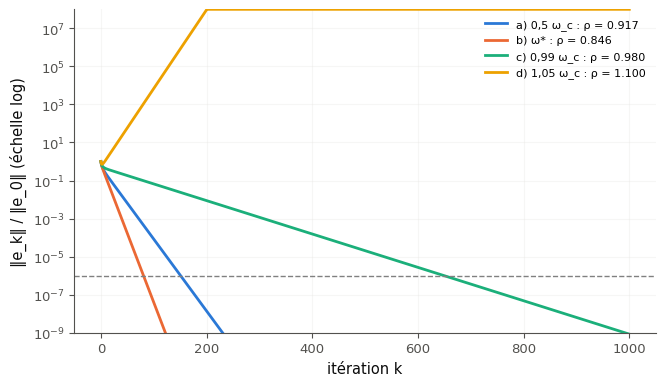

In [34]:
with checked("M19.23"):
    print("pas            ω         ρ(ω)     ⌈6 ln 10 / (−ln ρ)⌉   itérations comptées (1 000 pas au plus)")
    fig_23, ax_23 = plt.subplots(figsize=(7.5, 4.2))
    try:
        for name_23, omega_23 in OMEGAS_23.items():
            iterates_23 = mymath.iterative.richardson_iterates(A_23, B_23, omega_23, x0=X0_23, n_steps=1000)
            gains_23 = np.linalg.norm(iterates_23 - X_STAR_23, axis=1) / np.linalg.norm(X0_23 - X_STAR_23)
            reached_23 = np.flatnonzero(gains_23 <= 1e-6)
            rho_23 = max(abs(1 - omega_23 * 2), abs(1 - omega_23 * 24))
            formula_23 = f"{math.ceil(6 * math.log(10) / -math.log(rho_23)):8d}" if rho_23 < 1 else "     ∞  "
            counted_23 = (f"{reached_23[0]}" if reached_23.size else
                          f"jamais : l'écart a été multiplié par {gains_23[-1]:.1e}")
            print(f"{name_23:13} {omega_23:.5f}   {rho_23:.4f}   {formula_23}              {counted_23}")
            ax_23.semilogy(np.minimum(gains_23, 1e8), label=f"{name_23} : ρ = {rho_23:.3f}")
        ax_23.axhline(1e-6, color="0.5", ls="--", lw=1)
        ax_23.set_xlabel("itération k")
        ax_23.set_ylabel("‖e_k‖ / ‖e_0‖ (échelle log)")
        ax_23.set_ylim(1e-9, 1e8)
        ax_23.legend(fontsize=8)
        ax_23.grid(True, which="both", alpha=0.3)
    except BaseException:
        plt.close(fig_23)
        raise
    plt.show()

**Après l'expérience**, dans ta copie : pour chaque pas, laquelle des deux valeurs propres extrêmes décide de $\rho(\omega)$ ? Pourquoi, avec $0{,}5\,\omega_c$, la composante de $\lambda_{\max}$ disparaît-elle en un pas ? Pourquoi les comptes de l'expérience sont-ils un peu en dessous de la formule (que vaut $\lVert\mathbf{e}_0\rVert$ comparé à la composante la plus lente) ? Combien de fois $0{,}99\,\omega_c$ est-il plus lent que $\omega^\star$, alors qu'il est plus grand ?

💡 a) $0{,}5\,\omega_c = \frac{1}{24}$ : $\rho = \max(\frac{11}{12} ;\ 0) = \frac{11}{12}$, et la formule donne 159 itérations (choix 3) ; l'expérience en compte 151, car l'écart de départ n'a que la moitié de sa norme sur le vecteur propre le plus lent. b) $\omega^\star = \frac{1}{13}$ : $\rho = \frac{11}{13} = \frac{\kappa - 1}{\kappa + 1}$ avec $\kappa = 12$, 83 itérations (choix 2), 81 comptées. c) $0{,}99\,\omega_c$ : $\rho = \lvert 1 - 1{,}98\rvert = 0{,}98$, 684 itérations (choix 4), 650 comptées : huit fois plus lent que $\omega^\star$, bien que plus grand. d) $1{,}05\,\omega_c$ : $1 - 2{,}1 = -1{,}1$, la composante de $\lambda_{\max}$ grandit à chaque pas en changeant de signe (choix 5).

### Ex M19.24 — Le nombre d'itérations contre le conditionnement : une droite en échelle logarithmique 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer comment le nombre d'itérations de Richardson et du gradient conjugué croît avec le conditionnement, et lire l'exposant sur une droite en échelles logarithmiques.  
**Prérequis :** fiche §5 ; Ex M19.20 et M19.22 · **Parcours :** C

Les barres de M19.22, de plus en plus fines : pour chaque nombre $n$ de points intérieurs de `N_24` (de 2 à 50), `bar_24(n)` rend la matrice tridiagonale et le second membre (bouts à 10 °C et 70 °C ; cellule fournie). Plus la barre est fine, plus le système est mal conditionné. Pour chaque barre :
- son conditionnement $\kappa$, par la formule des valeurs propres de M19.22 ;
- le nombre d'itérations de Richardson au meilleur pas, depuis $\mathbf{0}$, jusqu'au premier itéré dont le résidu relatif $\lVert\mathbf{b} - \mathbf{A}\mathbf{x}_k\rVert/\lVert\mathbf{b}\rVert$ est $\le 10^{-6}$ (ta `richardson_iterates` ; 6 000 pas suffisent) ;
- le nombre d'itérations de `scipy.sparse.linalg.cg`, avec `rtol=1e-6` (il accepte aussi un tableau plein) et un `callback` qui compte.

Range-les dans `kappas_24`, `richardson_24` et `cg_24`, dans l'ordre de `N_24`. La cellule de vérification trace les deux comptes en fonction de $\kappa$, les deux axes en échelle logarithmique, avec les droites ajustées par `np.polyfit` sur $(\ln\kappa, \ln\text{compte})$ : une droite de pente $s$ veut dire un compte proportionnel à $\kappa^s$.

Réponds :
- a) le nombre d'itérations de Richardson pour la barre la plus fine, $n = 50$ (un entier) ;
- b) la pente de la droite de Richardson, arrondie au demi le plus proche (0,5 ; 1 ; 1,5 ou 2) ;
- c) la même pente pour le gradient conjugué, arrondie au demi le plus proche.

Dans ta copie : que vaut le meilleur pas pour toutes ces barres, et pourquoi ? Compare a) à $1{,}15\,\kappa\,d$ avec $d = 6$. Pourquoi le gradient conjugué fait-il ici exactement $n$ itérations, et comment $\kappa$ grandit-il avec $n$ (pour $n$ grand, $1 - \cos x \approx \frac{x^2}{2}$) ? Pour une barre de 1 000 points, combien d'itérations prévois-tu pour chaque méthode ?

In [35]:
N_24 = [2, 3, 5, 8, 13, 20, 32, 50]               # the inner points of eight bars, finer and finer


def bar_24(n):
    """The matrix tridiag(−1, 2, −1) of a bar with n inner points (a NumPy array), and its right-hand side, the ends
    being at 10 °C and 70 °C."""
    A = 2 * np.eye(n) - np.eye(n, k=1) - np.eye(n, k=-1)
    b = np.zeros(n)
    b[0], b[-1] = 10.0, 70.0
    return A, b

κ : [3.0, 5.8, 13.9, 32.2, 78.8, 178.1, 440.7, 1053.5]
Richardson : [20, 40, 91, 199, 466, 987, 2294, 5139] ; 1,15 κ d : [21, 40, 96, 222, 544, 1229, 3041, 7269]
gradient conjugué : [2, 3, 5, 8, 13, 20, 32, 50]
pentes : 0.942 0.548 -> 1.0 0.5


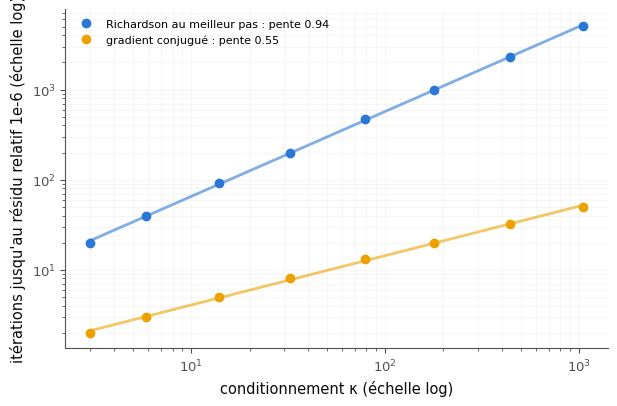

In [36]:
kappas_24, richardson_24, cg_24 = [], [], []
for n_24 in N_24:
    A_b24, b_b24 = bar_24(n_24)
    lambdas_24 = 2 - 2 * np.cos(np.arange(1, n_24 + 1) * np.pi / (n_24 + 1))
    kappas_24.append(float(lambdas_24.max() / lambdas_24.min()))
    omega_24 = 2 / (lambdas_24.min() + lambdas_24.max())
    iterates_24 = mymath.iterative.richardson_iterates(A_b24, b_b24, omega_24, n_steps=6000)
    relative_24 = np.linalg.norm(b_b24 - iterates_24 @ A_b24.T, axis=1) / np.linalg.norm(b_b24)
    richardson_24.append(int(np.flatnonzero(relative_24 <= 1e-6)[0]))
    calls_24 = []
    scipy.sparse.linalg.cg(A_b24, b_b24, rtol=1e-6, callback=lambda xk: calls_24.append(1))
    cg_24.append(len(calls_24))
slope_r24 = np.polyfit(np.log(kappas_24), np.log(richardson_24), 1)[0]
slope_c24 = np.polyfit(np.log(kappas_24), np.log(cg_24), 1)[0]
answer_M19_24a = richardson_24[-1]
answer_M19_24b = round(2 * slope_r24) / 2
answer_M19_24c = round(2 * slope_c24) / 2
print("κ :", np.round(kappas_24, 1).tolist())
print("Richardson :", richardson_24, "; 1,15 κ d :", [round(1.15 * k * 6) for k in kappas_24])
print("gradient conjugué :", cg_24)
print("pentes :", round(slope_r24, 3), round(slope_c24, 3), "->", answer_M19_24b, answer_M19_24c)

fig, ax = plt.subplots(figsize=(7.0, 4.4))
try:
    kappas_f24 = np.asarray(kappas_24, dtype=float)
    for counts_f24, label_f24, color_f24 in ((richardson_24, "Richardson au meilleur pas", "C0"),
                                             (cg_24, "gradient conjugué", "C3")):
        counts_f24 = np.asarray(counts_f24, dtype=float)
        slope_f24, intercept_f24 = np.polyfit(np.log(kappas_f24), np.log(counts_f24), 1)
        ax.loglog(kappas_f24, counts_f24, "o", color=color_f24, label=f"{label_f24} : pente {slope_f24:.2f}")
        ax.loglog(kappas_f24, np.exp(intercept_f24) * kappas_f24 ** slope_f24, "-", color=color_f24, alpha=0.6)
    ax.set_xlabel("conditionnement κ (échelle log)")
    ax.set_ylabel("itérations jusqu'au résidu relatif 1e-6 (échelle log)")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)
except BaseException:
    plt.close(fig)
    raise
plt.show()

In [37]:
counts_24r, kappas_24r, cg_24r = [], [], []
for n_24r in [2, 3, 5, 8, 13, 20, 32, 50]:
    a_24r = 2 * np.eye(n_24r) - np.eye(n_24r, k=1) - np.eye(n_24r, k=-1)
    b_24r = np.zeros(n_24r)
    b_24r[0], b_24r[-1] = 10.0, 70.0
    lambdas_24r = 2 - 2 * np.cos(np.arange(1, n_24r + 1) * np.pi / (n_24r + 1))
    kappas_24r.append(lambdas_24r.max() / lambdas_24r.min())
    x_24r, k_24r = np.zeros(n_24r), 0                 # Richardson at ω* = 1/2, step by step
    while np.linalg.norm(b_24r - a_24r @ x_24r) > 1e-6 * np.linalg.norm(b_24r):
        x_24r = x_24r + 0.5 * (b_24r - a_24r @ x_24r)
        k_24r += 1
    counts_24r.append(k_24r)
    calls_24r = []
    scipy.sparse.linalg.cg(a_24r, b_24r, rtol=1e-6, callback=lambda xk: calls_24r.append(1))
    cg_24r.append(len(calls_24r))
slopes_24r = [np.polyfit(np.log(kappas_24r), np.log(c), 1)[0] for c in (counts_24r, cg_24r)]
assert abs(slopes_24r[0] - 1) < 0.15 and abs(slopes_24r[1] - 0.5) < 0.1   # far from the next halves
wbm.record("M19.24a", counts_24r[-1])
wbm.record("M19.24b", round(2 * slopes_24r[0]) / 2, decimals=1, choices=[0.5, 1, 1.5, 2],
           mistakes={"Richardson demande de l'ordre de κ itérations (≈ 1,15 κ d) : relis la pente de sa droite":
                         {0.5, 1.5, 2}})
wbm.record("M19.24c", round(2 * slopes_24r[1]) / 2, decimals=1, choices=[0.5, 1, 1.5, 2],
           mistakes={"le gradient conjugué grandit bien plus lentement que Richardson : relis la pente de sa droite":
                         {1, 1.5, 2}})

WBM_ANSWER {"hash": "f2dfdd1a190027642ee12754662b0dad64106cc756c8f8880069f05da9160e9e", "id": "M19.24a", "kind": "int", "magnitude": 3, "sign": 1}
📝 Ex M19.24a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["0.5", "1.0", "1.5", "2.0"], "decimals": 1, "hash": "c523c055061b3f5e9620ba1c22820cbcfdb79239d7b345726c4752f78696bf9a", "hash_coarse": "13eff52738549082dfca5c7bc836c6f6b1c191b1527ae749fc9730179c28bb90", "id": "M19.24b", "kind": "float", "magnitude": 0, "mistakes": {"12cb7e25b0c9082c42c4f6a908a3c3810e8b36b8d8447beacafe9614eb9a9886": "Richardson demande de l'ordre de κ itérations (≈ 1,15 κ d) : relis la pente de sa droite", "150a84c72bf02fef6610359b1b89a1d668dc70bf6758b99b7697c98fdfe0a2d2": "Richardson demande de l'ordre de κ itérations (≈ 1,15 κ d) : relis la pente de sa droite", "e441d0f47a4ece601d48c1f9171a48fef60a6cd172d5e983f7f237a9aae26400": "Richardson demande de l'ordre de κ itérations (≈ 1,15 κ d) : relis la pente de sa droite"}, "sign": 1}
📝 Ex M19.24b : réponse enregi

**Après la figure**, dans ta copie : réponds aux questions de l'énoncé. Pour quelle taille de barre le gradient conjugué fait-il cent fois moins d'itérations que Richardson ?

💡 $\kappa$ va de 3 ($n = 2$) à $1\,053{,}5$ ($n = 50$). a) 5 139 itérations de Richardson pour $n = 50$, contre $1{,}15\,\kappa\,d \approx 7\,270$ pour le pire départ. b) La pente de Richardson vaut environ $0{,}94$ : 1, un compte proportionnel à $\kappa$ ; elle est un peu sous 1 parce que, pour les petites barres, $-\ln\frac{\kappa - 1}{\kappa + 1}$ dépasse $\frac{2}{\kappa}$. c) Le gradient conjugué fait exactement $n$ itérations (2, 3, 5… 50) ; comme $\kappa \approx \frac{4(n + 1)^2}{\pi^2}$ pour $n$ grand, $n$ grandit comme $\sqrt\kappa$ : pente $0{,}55$, soit $\frac12$. Le meilleur pas vaut $\frac12$ pour toutes les barres ($\lambda_{\min} + \lambda_{\max} = 4$). Pour 1 000 points, $\kappa \approx 4 \times 10^5$ : environ $3 \times 10^6$ itérations de Richardson, 1 000 du gradient conjugué.

## Partie C · Dessiner, déboguer, construire, défier

Fiche §1, §2, §4 et §6. Les itérés de Richardson sur les lignes de niveau ; trois erreurs classiques du chapitre ; un critère d'arrêt ; un défi : la stabilité du schéma saute-mouton d'un oscillateur. La vérification de M19.25 s'appuie sur la référence (`ref_iterative`), pour ne pas dépendre de ton code.

In [38]:
ref_iterative = wbm.load_mymath("ref", alias="mymath_ref").iterative   # the reference: the check of M19.25

### Ex M19.25 — Les itérés de Richardson sur les lignes de niveau d'une forme quadratique 🎨 ★ ⏱️ 20 min
**Objectif :** dessiner les itérés de Richardson sur les lignes de niveau de $\frac12\mathbf{x}^\top\mathbf{A}\mathbf{x} - \mathbf{b}^\top\mathbf{x}$, et voir l'effet du pas et du conditionnement.  
**Prérequis :** fiche §4 et §5 ; Ex M19.20 · **Parcours :** C, E

Richardson est une descente sur $f(\mathbf{x}) = \frac12\mathbf{x}^\top\mathbf{A}\mathbf{x} - \mathbf{b}^\top\mathbf{x}$ (fiche §4) : on la voit sur les lignes de niveau de $f$, des ellipses centrées en $\mathbf{x}^\star$, allongées dans la direction propre de $\lambda_{\min}$ (fiche §5). La cellule fournie donne $\mathbf{A} = \begin{pmatrix} 10 & 6 \\ 6 & 5 \end{pmatrix}$, de valeurs propres 14 et 1 ($\kappa = 14$ ; vecteurs propres $(3, 2)$ et $(2, -3)$), la solution $\mathbf{x}^\star = (1 ;\ -1)$, $\mathbf{b} = \mathbf{A}\mathbf{x}^\star$, le départ $\mathbf{x}_0 = (-2 ;\ 1)$, $N = 25$ pas, et trois pas : la moitié du pas critique, le meilleur pas et $0{,}95\,\omega_c$ (`OMEGAS_25`).

Écris `draw_richardson(ax, A, b, omega, x0, n_steps)`, qui dessine dans l'axe `ax` (sans en ouvrir d'autre) :
- les lignes de niveau de $f$ : `ax.contour(X, Y, F, levels=...)`, avec `X, Y = np.meshgrid(xs, ys)` sur une grille qui contient tous les itérés, et `F` la valeur de $f$ en chaque point de la grille (`F = 0.5 * (A[0, 0] * X**2 + 2 * A[0, 1] * X * Y + A[1, 1] * Y**2) - b[0] * X - b[1] * Y`) ;
- les itérés $\mathbf{x}_0, \ldots, \mathbf{x}_N$ que rend ta `richardson_iterates`, reliés dans l'ordre par **une seule** ligne avec des points : `ax.plot(xs[:, 0], xs[:, 1], "o-")` ;
- la solution $\mathbf{x}^\star$, marquée d'un point (`np.linalg.solve` est permis ici) ;
- la même échelle sur les deux axes (`ax.set_aspect("equal")`), et un titre qui donne $\omega$.

La vérification appelle ta fonction pour les trois pas, côte à côte, et regarde le dessin : les lignes de niveau, une ligne qui passe par les $N + 1$ itérés de la référence, dans l'ordre, la solution marquée, et les échelles égales.

In [39]:
A_25 = np.array([[10.0, 6.0],
                 [6.0, 5.0]])                   # symmetric positive definite, eigenvalues 14 and 1
X_STAR_25 = np.array([1.0, -1.0])               # the solution
B_25 = A_25 @ X_STAR_25
X0_25 = np.array([-2.0, 1.0])                   # the start
N_25 = 25                                       # the number of steps
OMEGA_C_25 = 2 / 14                             # the critical step
OMEGAS_25 = [0.5 * OMEGA_C_25, 2 / (1 + 14), 0.95 * OMEGA_C_25]   # half of it, the best step, just below it

✅ draw_richardson dessine dans l'axe reçu
✅ les lignes de niveau sont tracées (ax.contour)
✅ les 26 itérés x₀, …, x_N sont reliés par une ligne, dans l'ordre
✅ la solution x* est marquée
✅ les deux axes ont la même échelle : les ellipses ne sont pas déformées


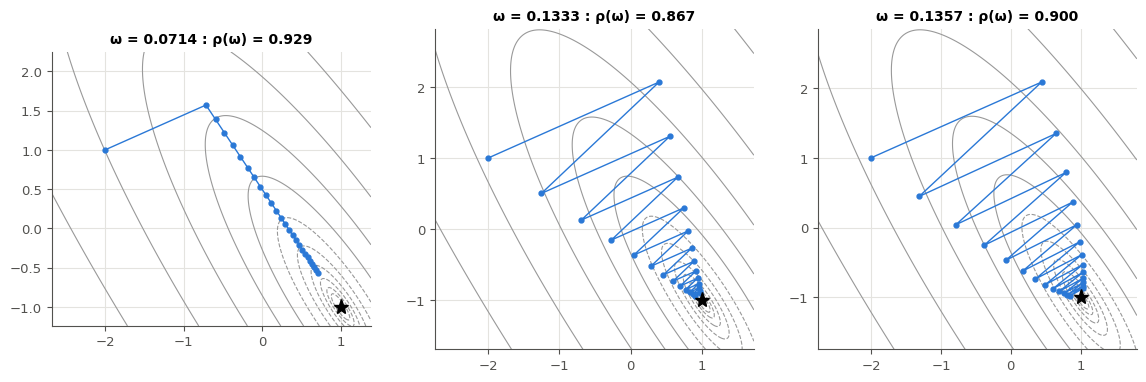

✅ Ex M19.25 : les lignes de niveau, les itérés et la solution sont dessinés pour les trois pas.


In [40]:
def draw_richardson(ax, A, b, omega, x0, n_steps):
    """In ax (and no other axes): the level lines of f(x) = ½ xᵀ A x − bᵀ x, the iterates x_0, ..., x_N of
    Richardson's method joined in order by one line with markers, the solution marked, equal scales, a title."""
    A, b = np.asarray(A, dtype=float), np.asarray(b, dtype=float)
    path = mymath.iterative.richardson_iterates(A, b, omega, x0=x0, n_steps=n_steps)
    x_star = np.linalg.solve(A, b)
    low, high = path.min(axis=0), path.max(axis=0)
    margin = 0.25 * max(high - low)
    X, Y = np.meshgrid(np.linspace(low[0] - margin, high[0] + margin, 200),
                       np.linspace(low[1] - margin, high[1] + margin, 200))
    F = 0.5 * (A[0, 0] * X ** 2 + 2 * A[0, 1] * X * Y + A[1, 1] * Y ** 2) - b[0] * X - b[1] * Y
    f_star = -0.5 * b @ x_star                                # the minimum of f
    ax.contour(X, Y, F, levels=f_star + np.geomspace(0.02, 1.2 * (F.max() - f_star), 12), colors="0.6",
               linewidths=0.8)
    ax.plot(path[:, 0], path[:, 1], "o-", color="C0", ms=3.5, lw=1)
    ax.plot(x_star[0], x_star[1], "k*", ms=11)
    ax.set_aspect("equal")
    rho = max(abs(1 - omega * lam) for lam in np.linalg.eigvalsh(A))
    ax.set_title(f"ω = {omega:.4f} : ρ(ω) = {rho:.3f}", fontsize=10)


with checked("M19.25"):
    results_25 = []

    def report_25(ok, success, failure):
        results_25.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))

    fig_25, axes_25 = plt.subplots(1, 3, figsize=(14.0, 4.6))
    try:
        opened_25, contour_25, path_25, star_25, aspect_25 = [], [], [], [], []
        for ax_25, omega_25 in zip(axes_25, OMEGAS_25):
            opened_25 += drawn(draw_richardson, ax_25, A_25, B_25, omega_25, X0_25, N_25)
            want_25 = ref_iterative.richardson_iterates(A_25, B_25, omega_25, x0=X0_25, n_steps=N_25)
            contour_25.append(any(isinstance(item, ContourSet) for item in ax_25.collections))
            path_25.append(any(np.shape(line.get_xydata()) == want_25.shape
                               and np.allclose(line.get_xydata(), want_25, rtol=1e-9, atol=1e-9)
                               for line in ax_25.lines))
            points_25 = [np.asarray(line.get_xydata(), dtype=float).reshape(-1, 2) for line in ax_25.lines]
            points_25 += [np.asarray(item.get_offsets(), dtype=float).reshape(-1, 2) for item in ax_25.collections
                          if not isinstance(item, ContourSet)]
            star_25.append(any(len(p) and np.min(np.linalg.norm(p - X_STAR_25, axis=1)) < 1e-6 for p in points_25))
            aspect_25.append(ax_25.get_aspect() in ("equal", 1.0))
        report_25(not opened_25, "draw_richardson dessine dans l'axe reçu",
                  "draw_richardson doit dessiner dans l'axe reçu, sans ouvrir de figure (ni plt.figure ni plt.subplots)")
        report_25(all(contour_25), "les lignes de niveau sont tracées (ax.contour)",
                  f"pas de lignes de niveau (ax.contour) dans {contour_25.count(False)} des trois axes")
        report_25(all(path_25), f"les {N_25 + 1} itérés x₀, …, x_N sont reliés par une ligne, dans l'ordre",
                  "aucune ligne ne passe par les itérés x₀, …, x_N, tous et dans l'ordre, pour "
                  f"{path_25.count(False)} des trois pas : ax.plot(xs[:, 0], xs[:, 1], \"o-\"), avec xs le tableau "
                  "de richardson_iterates (x0, n_steps)")
        report_25(all(star_25), "la solution x* est marquée",
                  "marque la solution x* d'un point (ax.plot(x_star[0], x_star[1], \"k*\")), dans chaque axe")
        report_25(all(aspect_25), "les deux axes ont la même échelle : les ellipses ne sont pas déformées",
                  "donne la même échelle aux deux axes : ax.set_aspect(\"equal\")")
    except BaseException:
        plt.close(fig_25)
        raise
    plt.show()
    verdict("M19.25", all(results_25), "les lignes de niveau, les itérés et la solution sont dessinés pour les trois "
                                       "pas.", "relis les lignes ❌ ci-dessus.")

**Regarde ta figure**, puis, dans ta copie : pour chaque pas, que vaut le facteur $1 - \omega\lambda$ dans la direction raide $(3, 2)$, et dans la direction plate $(2, -3)$ ? Pourquoi, avec la moitié du pas critique, le premier pas tombe-t-il droit sur l'axe long de l'ellipse ? Pourquoi les itérés zigzaguent-ils d'un bord à l'autre avec $0{,}95\,\omega_c$ ? Le long de l'axe long, lequel des trois pas progresse le plus vite, et de combien, au plus, un pas permis peut-il y faire progresser ? Que verrais-tu avec $1{,}05\,\omega_c$ ?

💡 Les facteurs $(1 - 14\omega ;\ 1 - \omega)$ valent $(0 ;\ \frac{13}{14})$ pour $\omega = \frac{1}{14}$, $(-\frac{13}{15} ;\ \frac{13}{15})$ pour $\omega^\star = \frac{2}{15}$, et $(-0{,}9 ;\ 0{,}864)$ pour $0{,}95\,\omega_c$. Avec la moitié du pas critique, la composante raide disparaît en un pas : $\mathbf{x}_1$ est sur l'axe long, puis les itérés le descendent sans osciller. Au meilleur pas, les deux composantes diminuent au même rythme, la raide en changeant de signe. Juste sous le pas critique, la composante raide change de signe et ne diminue que de 10 % par pas : les itérés sautent d'un bord à l'autre des ellipses. Le long de l'axe long, le facteur $1 - \omega$ ne descend jamais sous $1 - \frac{2}{14} \approx 0{,}857$ : quel que soit le pas permis, la direction plate avance lentement ; c'est le conditionnement. Avec $1{,}05\,\omega_c$, $1 - 14\omega = -1{,}1$ : les sauts grandissent, l'itération diverge.

### Ex M19.26 — Chasse à l'erreur : un pas réglé sur λmin, une hessienne non symétrique, le module d'une racine complexe 🐛 ★ ⏱️ 15 min
**Objectif :** reconnaître trois erreurs classiques du chapitre qui ne lèvent aucune erreur Python et passent une vérification mal choisie, puis les corriger.  
**Prérequis :** fiche §1, §2, §4 et §6 · **Parcours :** C, E

Un collègue a écrit trois morceaux de code (cellule fournie) ; chacun a l'erreur que nomme le titre, aucun ne lève d'erreur Python, et chacun a passé la vérification que le collègue a faite :
1. `critical_26(A)` doit rendre le pas critique $\frac{2}{\lambda_{\max}}$ d'une matrice symétrique définie positive. Il l'a vérifiée sur $4\mathbf{I}$ : 0,5, juste. Puis il a lancé Richardson sur le système des trois masses `K_26`, `F_26` avec la moitié de ce pas, « par prudence » : les itérés explosent.
2. `hessian_26(f, x, h)` calcule la hessienne par différences centrées, chaque case de la diagonale et au-dessus une seule fois ; `nature_26(H)` lit la nature d'un point critique sur les signes de `np.linalg.eigvalsh(H)`. Il les a vérifiées sur $\cos x + y^2 + z^2$ en $\mathbf{0}$, une selle : juste.
3. `converges_26(p, q)` doit dire si toutes les solutions de $u_{k+2} = p\,u_{k+1} - q\,u_k$ tendent vers 0. Il l'a vérifiée sur les trois récurrences de la fiche (§6), $(p, q) = (1 ;\ 0{,}21)$, $(0{,}8 ;\ 0{,}64)$ et $(1{,}5 ;\ -1)$ : juste.

À faire :
- a) avec le pas du collègue, $\omega$ = `critical_26(K_26) / 2` : le facteur $\rho(\omega) = \max_i\lvert 1 - \omega\lambda_i\rvert$ sur les valeurs propres de `K_26` (un nombre, 4 décimales) ;
- (1) écris `critical_26_fixed(A)` ;
- (2) écris `hessian_26_fixed(f, x, h=1e-4)` ; b) avec elle et `nature_26`, la nature du point critique $\mathbf{0}$ de $g(x, y, z) = x^2 + y^2 + z^2 + 3\sin x\sin y + yz$ (`g_26`) : (A) minimum local ; (B) maximum local ; (C) point selle ; (D) le test ne conclut pas (une lettre entre guillemets) ;
- (3) écris `converges_26_fixed(p, q)` ; c) le module des racines de $r^2 - r + 1{,}2$, c'est-à-dire pour $(p, q) = (1 ;\ 1{,}2)$ (4 décimales).

La vérification essaie tes corrections sur des cas que tu ne vois pas : d'autres matrices, d'autres fonctions et d'autres points, une grille de couples $(p, q)$.

In [41]:
K_26 = np.array([[3.0, -2.0, 0.0],
                 [-2.0, 5.0, -3.0],
                 [0.0, -3.0, 9.0]])            # three masses, four springs of stiffness 1, 2, 3 and 6
F_26 = np.array([1.0, 0.0, 2.0])               # the forces on the masses


# The colleague's code
def critical_26(A):
    """The critical step 2 / λmax of a symmetric positive definite matrix A."""
    return 2.0 / np.linalg.eigvalsh(A)[0]


def hessian_26(f, x, h=1e-4):
    """The Hessian of f at x by centered differences: each entry on or above the diagonal is computed once."""
    x = np.asarray(x, dtype=float)
    n = len(x)
    E = h * np.eye(n)
    H = np.zeros((n, n))
    for i in range(n):
        H[i, i] = (f(x + E[i]) - 2 * f(x) + f(x - E[i])) / h ** 2
        for j in range(i + 1, n):
            H[i, j] = (f(x + E[i] + E[j]) - f(x + E[i] - E[j]) - f(x - E[i] + E[j]) + f(x - E[i] - E[j])) / (4 * h ** 2)
    return H


def nature_26(H, tol=1e-6):
    """The nature of a critical point read on the signs of the eigenvalues of its (symmetric) Hessian H:
    "minimum", "maximum", "selle", or "?" when the test does not conclude."""
    values = np.linalg.eigvalsh(H)
    if np.all(values > tol):
        return "minimum"
    if np.all(values < -tol):
        return "maximum"
    if np.any(values > tol) and np.any(values < -tol):
        return "selle"
    return "?"


def converges_26(p, q):
    """True when every solution of u_{k+2} = p u_{k+1} − q u_k tends to 0: both roots of r² − p r + q have a modulus
    < 1."""
    delta = p * p - 4 * q
    if delta >= 0:                                     # two real roots
        roots = [(p + math.sqrt(delta)) / 2, (p - math.sqrt(delta)) / 2]
        return max(abs(r) for r in roots) < 1
    modulus = abs(p) / 2                               # complex roots p/2 ± i √(−Δ)/2
    return modulus < 1


def g_26(v):
    """g(x, y, z) = x² + y² + z² + 3 sin x sin y + y z, for v = (x, y, z): the origin is a critical point."""
    x, y, z = v
    return x ** 2 + y ** 2 + z ** 2 + 3 * np.sin(x) * np.sin(y) + y * z


# The colleague's checks: all pass
print("(1) critical_26(4 I) =", critical_26(4 * np.eye(3)))
print("(2) nature_26 de cos x + y² + z² en 0 :",
      nature_26(hessian_26(lambda v: np.cos(v[0]) + v[1] ** 2 + v[2] ** 2, np.zeros(3))))
print("(3) converges_26 pour les trois récurrences de la fiche :",
      [converges_26(p, q) for p, q in ((1.0, 0.21), (0.8, 0.64), (1.5, -1.0))])
omega_26 = critical_26(K_26) / 2                 # « half the critical step, to be safe »
x_26 = np.zeros(3)
for k_26 in range(1, 31):
    x_26 = x_26 + omega_26 * (F_26 - K_26 @ x_26)
    if k_26 % 10 == 0:
        print(f"(1) Richardson sur K_26 x = F_26 avec ce pas, itération {k_26} : ‖x‖ = {np.linalg.norm(x_26):.3g}")

(1) critical_26(4 I) = 0.5
(2) nature_26 de cos x + y² + z² en 0 : selle
(3) converges_26 pour les trois récurrences de la fiche : [True, True, False]
(1) Richardson sur K_26 x = F_26 avec ce pas, itération 10 : ‖x‖ = 3.85e+07
(1) Richardson sur K_26 x = F_26 avec ce pas, itération 20 : ‖x‖ = 8.6e+15
(1) Richardson sur K_26 x = F_26 avec ce pas, itération 30 : ‖x‖ = 1.92e+24


In [42]:
lambdas_26 = np.linalg.eigvalsh(K_26)
answer_M19_26a = float(max(abs(1 - omega_26 * lambdas_26)))
print("valeurs propres de K_26 :", np.round(lambdas_26, 4).tolist(), "; ω du collègue :", round(omega_26, 4),
      "; pas critique :", round(2 / lambdas_26[-1], 4))


def critical_26_fixed(A):
    """The critical step 2 / λmax of a symmetric positive definite matrix A."""
    return float(2.0 / np.linalg.eigvalsh(A)[-1])           # eigvalsh: increasing order, λmax is the LAST one


def hessian_26_fixed(f, x, h=1e-4):
    """The Hessian of f at x by centered differences, exactly symmetric."""
    H = hessian_26(f, x, h)                                    # the diagonal and the upper triangle are right
    return np.triu(H) + np.triu(H, k=1).T                      # copy the upper triangle below


def converges_26_fixed(p, q):
    """True when every solution of u_{k+2} = p u_{k+1} − q u_k tends to 0: both roots of r² − p r + q have a modulus
    < 1."""
    delta = p * p - 4 * q
    if delta >= 0:
        roots = [(p + math.sqrt(delta)) / 2, (p - math.sqrt(delta)) / 2]
        return max(abs(r) for r in roots) < 1
    return math.sqrt(q) < 1                                    # conjugate roots: their product q is |r|²


answer_M19_26b = {"minimum": "A", "maximum": "B", "selle": "C", "?": "D"}[nature_26(hessian_26_fixed(g_26, np.zeros(3)))]
answer_M19_26c = math.sqrt(1.2)
print("a)", round(answer_M19_26a, 4), " b)", answer_M19_26b, "; le collègue :", nature_26(hessian_26(g_26, np.zeros(3))),
      "; valeurs propres :", np.round(np.linalg.eigvalsh(hessian_26_fixed(g_26, np.zeros(3))), 4).tolist())
print("c)", round(answer_M19_26c, 4), "; (p, q) = (1 ; 1,2) : le collègue dit", converges_26(1.0, 1.2),
      "; |u_k| pour k = 20, 40, 60 :", np.round(np.abs(mymath.iterative.linear_recurrence([1.0, -1.2], [1.0, 0.0], 61)
                                                      [[20, 40, 60]]), 2).tolist())


results_26, parts_26 = [], []


def report_26(ok, success, failure):
    results_26.append(bool(ok))
    print(("✅ " + success) if ok else ("❌ " + failure))


with checked("M19.26"):                                       # (1) critical_26_fixed
    rng_26 = np.random.default_rng(5236)
    wrong_26 = []
    for n_26 in (1, 2, 3, 5):
        Q_c26, _ = np.linalg.qr(rng_26.normal(size=(n_26, n_26)))
        values_c26 = np.sort(rng_26.uniform(0.3, 9.0, size=n_26))
        A_c26 = Q_c26 @ np.diag(values_c26) @ Q_c26.T
        A_c26 = (A_c26 + A_c26.T) / 2
        got_26 = critical_26_fixed(A_c26.copy())
        if got_26 is None or not math.isclose(float(got_26), 2 / values_c26[-1], rel_tol=1e-9):
            wrong_26.append(f"une matrice {n_26} × {n_26} de valeurs propres {np.round(values_c26, 2).tolist()} : "
                            f"attendu {2 / values_c26[-1]:.6g}, reçu {got_26!r}"[:200])
    report_26(not wrong_26, "(1) critical_26_fixed : le pas critique de quatre matrices",
              "(1) critical_26_fixed, " + " ; ".join(wrong_26[:2]))
    parts_26.append(1)

with checked("M19.26"):                                       # (2) hessian_26_fixed
    xyz_26 = sympy.symbols("x y z")
    cases_26 = [(sympy.sin(xyz_26[0] * xyz_26[1]) + xyz_26[0] * xyz_26[2] ** 2, 3),
                (sympy.log(2 + xyz_26[0] ** 2) + xyz_26[1] * xyz_26[2] ** 3, 3),
                (xyz_26[0] ** 3 * xyz_26[1] - sympy.cos(xyz_26[1]), 2),
                (xyz_26[0] ** 2 + xyz_26[1] ** 2 + xyz_26[2] ** 2 + 3 * sympy.sin(xyz_26[0]) * sympy.sin(xyz_26[1])
                 + xyz_26[1] * xyz_26[2], 3)]                 # g_26
    rng_26 = np.random.default_rng(5237)
    wrong_26 = []
    for expr_26, n_26 in cases_26:
        symbols_26 = xyz_26[:n_26]
        f_c26 = sympy.lambdify([symbols_26], expr_26, "numpy")
        point_26 = rng_26.uniform(-1.5, 1.5, size=n_26)
        exact_26 = np.array(sympy.hessian(expr_26, symbols_26).subs(dict(zip(symbols_26, point_26))), dtype=float)
        got_26 = hessian_26_fixed(f_c26, point_26.copy())
        shape_26 = np.shape(got_26) if got_26 is not None else None
        if shape_26 != (n_26, n_26):
            wrong_26.append(f"pour {expr_26} : attendu une matrice {n_26} × {n_26}, reçu {got_26!r}"[:160])
        elif not np.array_equal(np.asarray(got_26), np.asarray(got_26).T):
            wrong_26.append(f"pour {expr_26} : la matrice n'est pas exactement symétrique")
        elif not np.allclose(got_26, exact_26, rtol=1e-5, atol=1e-5):
            wrong_26.append(f"pour {expr_26} en {np.round(point_26, 3).tolist()} : attendu "
                            f"{np.round(exact_26, 4).tolist()}, reçu {np.round(got_26, 4).tolist()}"[:240])
    report_26(not wrong_26, "(2) hessian_26_fixed : quatre fonctions en des points tirés au hasard, symétrique",
              "(2) hessian_26_fixed, " + " ; ".join(wrong_26[:2]))
    exact_g26 = np.array(sympy.hessian(cases_26[-1][0], xyz_26).subs(dict.fromkeys(xyz_26, 0)), dtype=float)
    seen_26 = nature_26(hessian_26_fixed(g_26, np.zeros(3)))
    report_26(seen_26 == nature_26(exact_g26), "(2) avec hessian_26_fixed, nature_26 lit en 0 la même nature que sur "
                                               "la hessienne exacte de g_26",
              f"(2) avec hessian_26_fixed, nature_26 dit {seen_26!r} pour g_26 en 0, autre chose qu'avec la hessienne "
              "exacte")
    parts_26.append(2)

with checked("M19.26"):                                       # (3) converges_26_fixed
    wrong_26, tried_26 = [], 0
    for p_26 in np.linspace(-2.5, 2.5, 21):
        for q_26 in np.linspace(-1.35, 1.65, 21):
            if min(abs(abs(q_26) - 1), abs(abs(p_26) - (1 + q_26))) < 1e-9:
                continue                                      # on the border of the triangle: not tried
            tried_26 += 1
            want_26 = bool(np.max(np.abs(np.roots([1.0, -p_26, q_26]))) < 1)
            got_26 = converges_26_fixed(float(p_26), float(q_26))
            if got_26 is None or bool(got_26) != want_26:
                wrong_26.append(f"(p, q) = ({p_26:.2f} ; {q_26:.2f}) : attendu {want_26}, reçu {got_26!r}")
    report_26(not wrong_26, f"(3) converges_26_fixed : juste sur une grille de {tried_26} couples (p, q)",
              f"(3) converges_26_fixed se trompe pour {len(wrong_26)} couple(s) sur {tried_26}, par exemple "
              + " ; ".join(wrong_26[:2]))
    parts_26.append(3)

if len(parts_26) == 3:
    verdict("M19.26", all(results_26), "les trois fonctions corrigées passent tous les cas.",
            "relis les lignes ❌ ci-dessus.")

valeurs propres de K_26 : [1.3687, 4.9038, 10.7275] ; ω du collègue : 0.7306 ; pas critique : 0.1864
a) 6.8379  b) C ; le collègue : minimum ; valeurs propres : [-1.1623, 2.0, 5.1623]
c) 1.0954 ; (p, q) = (1 ; 1,2) : le collègue dit True ; |u_k| pour k = 20, 40, 60 : [6.36, 40.26, 254.13]
✅ (1) critical_26_fixed : le pas critique de quatre matrices


✅ (2) hessian_26_fixed : quatre fonctions en des points tirés au hasard, symétrique
✅ (2) avec hessian_26_fixed, nature_26 lit en 0 la même nature que sur la hessienne exacte de g_26
✅ (3) converges_26_fixed : juste sur une grille de 433 couples (p, q)
✅ Ex M19.26 : les trois fonctions corrigées passent tous les cas.


In [43]:
k_26r = np.array([[3.0, -2.0, 0.0], [-2.0, 5.0, -3.0], [0.0, -3.0, 9.0]])
lambdas_26r = np.linalg.eigvalsh(k_26r)
omega_26r = (2 / lambdas_26r[0]) / 2                                 # the colleague's step: half of 2/λmin
wbm.record("M19.26a", max(abs(1 - omega_26r * lambdas_26r)), decimals=4,
           mistakes={"le collègue prend la MOITIÉ de ce que rend critical_26": max(abs(1 - 2 * omega_26r * lambdas_26r)),
                     "avec le pas du collègue, pas avec un pas juste : ρ(ω) pour ω = critical_26(K_26) / 2":
                         max(abs(1 - lambdas_26r / lambdas_26r[-1]))})
hessian_g_26r = np.array([[2.0, 3.0, 0.0], [3.0, 2.0, 1.0], [0.0, 1.0, 2.0]])   # the exact Hessian of g at 0
assert np.linalg.eigvalsh(hessian_g_26r)[0] < 0 < np.linalg.eigvalsh(hessian_g_26r)[-1]
wbm.record("M19.26b", "C",
           mistakes={"c'est ce que dit la hessienne du collègue : eigvalsh ne lit qu'un triangle de la matrice, et la "
                     "tienne doit être symétrique": "A",
                     "des valeurs propres des deux signes : relis le test du second ordre (fiche §2)": {"B", "D"}})
wbm.record("M19.26c", math.sqrt(1.2), decimals=4,
           mistakes={"le module de racines complexes conjuguées est √q, pas leur partie réelle |p|/2": 0.5,
                     "le module est √q : q est le produit des deux racines conjuguées, le carré de leur module": 1.2})

WBM_ANSWER {"coarse_any": {"0": ["67aa1232865540ec5a93e15344c59d0e1a2071779c139d559eb031e655a0f46b"]}, "coarser": {"1": ["d793ccf7eb9afb7536fb3d813de4008b7f329cc464c37c473b73ae23c6568c44"], "2": ["5d008cf49a03ecae19931dbf77a1b70c5880ed0cb017021a5a0faaa9f2722547"]}, "decimals": 4, "hash": "a728aa295f9faa8fbcf2b9726f0cc066ce17fdc2ccf52afbe2f9e5f6d41c560d", "hash_coarse": "85776c4c82d2d5be37bc099671699a3c59a542fb7bcfdfdefbfb58dfcff3a880", "id": "M19.26a", "kind": "float", "magnitude": 0, "mistakes": {"1bb13a90baa4e783a8d2751dcb6dfc54dc827b190c5fccb96b5b85effc2ee41e": "avec le pas du collègue, pas avec un pas juste : ρ(ω) pour ω = critical_26(K_26) / 2", "64db9d1306b9a28d49c7821e4e498b9dc689c1ca2716c7b06debb2595bfe87ed": "le collègue prend la MOITIÉ de ce que rend critical_26"}, "sign": 1}
📝 Ex M19.26a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"hash": "30f0f901ea5b8b3925fc41e7677beca5003704e8f6291f048ed59d7332614358", "id": "M19.26b", "kind": "str", "mistakes": {"6f19a36639b9

**Après la vérification**, dans ta copie : sur $4\mathbf{I}$, pourquoi la vérification du collègue ne pouvait-elle pas voir l'erreur (1) ? Que fait `np.linalg.eigvalsh` d'une matrice dont seul le triangle supérieur est rempli (lis la documentation de son argument `UPLO`), et pourquoi la fonction de test du collègue, $\cos x + y^2 + z^2$, ne pouvait-elle pas voir l'erreur (2) ? Les trois récurrences de la fiche passent le test (3) : pour laquelle des trois $\lvert p\rvert/2$ et $\sqrt q$ sont-ils tous deux $< 1$, et quelles autres récurrences auraient démasqué l'erreur ?

💡 a) $\mathbf{K}$ a pour valeurs propres $1{,}3687$ ; $4{,}9038$ et $10{,}7275$. `eigvalsh` les rend en ordre croissant : `[0]` est $\lambda_{\min}$, et le pas du collègue vaut $\frac{1}{\lambda_{\min}} \approx 0{,}7306$, près de quatre fois le pas critique $\frac{2}{\lambda_{\max}} \approx 0{,}1864$ ; $\rho = \frac{\lambda_{\max}}{\lambda_{\min}} - 1 \approx 6{,}8379$. Sur $4\mathbf{I}$, toutes les valeurs propres sont égales : `[0]` et `[-1]` donnent le même pas. b) La hessienne exacte de $g$ en $\mathbf{0}$ est $\begin{pmatrix} 2 & 3 & 0 \\ 3 & 2 & 1 \\ 0 & 1 & 2 \end{pmatrix}$, de valeurs propres $2 - \sqrt{10}$, 2 et $2 + \sqrt{10}$ : une selle. `eigvalsh` lit par défaut le triangle **inférieur** (`UPLO='L'`) ; celui du collègue est vide, `eigvalsh` voit $\operatorname{diag}(2, 2, 2)$ et conclut « minimum ». Sur $\cos x + y^2 + z^2$, la hessienne est diagonale : aucun triangle ne manque. c) $\Delta = 1 - 4{,}8 < 0$ : les racines $0{,}5 \pm 0{,}975i$ ont pour module $\sqrt{1{,}2} \approx 1{,}0954 > 1$, et la suite diverge en oscillant ; le collègue lit $\frac{\lvert p\rvert}{2} = 0{,}5$. Pour $(0{,}8 ;\ 0{,}64)$, $0{,}4$ et $0{,}8$ sont tous deux $< 1$ : il faut $q > 1$ et $\lvert p\rvert < 2$ pour démasquer l'erreur.

### Ex M19.27 — Un critère d'arrêt : le résidu relatif ‖b − A x‖/‖b‖ et un nombre maximal d'itérations 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire une itération de Richardson qui s'arrête d'elle-même, au premier itéré assez précis, et qui sait dire qu'elle n'a pas convergé.  
**Prérequis :** fiche §4 (💻) ; Ex M19.20 · **Parcours :** C

Une méthode itérative utilisable ne fait pas un nombre de pas fixé d'avance : elle s'arrête quand le **résidu relatif** $\frac{\lVert\mathbf{b} - \mathbf{A}\mathbf{x}_k\rVert}{\lVert\mathbf{b}\rVert}$ passe sous une tolérance, et abandonne après un nombre maximal d'itérations (fiche §4, 💻). Écris `solve_richardson(A, b, omega, tol=1e-8, max_iter=10_000)`, qui part de $\mathbf{x}_0 = \mathbf{0}$ et rend le triplet `(x, n_iter, converged)` ; pour $k = 0, 1, 2, \ldots$, elle calcule le résidu relatif de l'itéré courant $\mathbf{x}_k$ :
- s'il est $\le$ `tol` : elle rend `(x_k, k, True)` ;
- sinon, s'il n'est plus un nombre fini, ou s'il dépasse $10^{10}$ (l'itération diverge : inutile d'attendre l'overflow), ou si $k$ = `max_iter` : elle rend `(x_k, k, False)` ;
- sinon, elle fait un pas de Richardson, $\mathbf{x}_{k+1} = \mathbf{x}_k + \omega(\mathbf{b} - \mathbf{A}\mathbf{x}_k)$.

`n_iter` est donc le nombre de pas faits, et le **premier** $k$ qui arrête la boucle : pas une itération de plus. `b` n'est pas nul ; `A` et `b` ne sont pas modifiés ; aucun `RuntimeWarning` (un overflow) ne doit apparaître.

La cellule fournie donne le système de quatre masses entre deux murs, reliées par cinq ressorts, `K_27` $\mathbf{x}$ = `F_27`. La vérification lance ta fonction sur ce système avec un bon pas ($\frac{1}{\lambda_{\max}}$), avec `tol=1e-3`, avec `tol=1` (le départ suffit déjà), avec `max_iter=15`, avec un pas trop grand ($1{,}2\,\omega_c$), puis sur trois systèmes tirés au hasard, compare chaque triplet à celui de la règle ci-dessus, et compare la solution de `K_27` à `np.linalg.solve` (permis ici, pour vérifier).

Dans ta copie : pourquoi tester le résidu **avant** de faire un pas, et pas après ? Le résidu relatif mesure-t-il l'erreur sur $\mathbf{x}$ ? Montre que $\frac{\lVert\mathbf{x}_k - \mathbf{x}^\star\rVert}{\lVert\mathbf{x}^\star\rVert} \le \kappa\,\frac{\lVert\mathbf{b} - \mathbf{A}\mathbf{x}_k\rVert}{\lVert\mathbf{b}\rVert}$ (M12d), et dis ce que cela veut dire pour un système mal conditionné. Pourquoi un seuil $10^{10}$ suffit-il ici pour conclure à la divergence ?

In [44]:
K_27 = np.array([[4.0, -1.0, 0.0, 0.0],
                 [-1.0, 3.0, -2.0, 0.0],
                 [0.0, -2.0, 3.0, -1.0],
                 [0.0, 0.0, -1.0, 4.0]])       # four masses, five springs of stiffness 3, 1, 2, 1, 3 between two walls
F_27 = np.array([1.0, 0.0, 0.0, 2.0])         # the forces on the masses

In [45]:
def solve_richardson(A, b, omega, tol=1e-8, max_iter=10_000):
    """Richardson's iteration from x_0 = 0 for A x = b, stopped at the first k whose relative residual
    ‖b − A x_k‖ / ‖b‖ is ≤ tol (converged), or is not finite or above 1e10, or when k = max_iter (not converged).
    Returns (x_k, k, converged)."""
    A, b = np.asarray(A, dtype=float), np.asarray(b, dtype=float)
    norm_b = np.linalg.norm(b)
    x, k = np.zeros(len(b)), 0
    while True:
        residual = b - A @ x
        relative = np.linalg.norm(residual) / norm_b
        if relative <= tol:
            return x, k, True
        if not np.isfinite(relative) or relative > 1e10 or k == max_iter:
            return x, k, False
        x = x + omega * residual                               # one step, with the residual already computed
        k += 1


lambdas_s27 = np.linalg.eigvalsh(K_27)
for label_s27, omega_s27 in (("1/λmax", 1 / lambdas_s27[-1]), ("ω*", 2 / (lambdas_s27[0] + lambdas_s27[-1])),
                             ("1,2 ω_c", 2.4 / lambdas_s27[-1])):
    x_s27, n_s27, converged_s27 = solve_richardson(K_27, F_27, omega_s27)
    print(f"ω = {label_s27} : {n_s27} itérations, converged = {converged_s27}, x = {np.round(x_s27, 6).tolist()}")


with checked("M19.27"):
    results_27 = []

    def report_27(ok, success, failure):
        results_27.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))

    def expected_27(A, b, omega, tol, max_iter):
        """The expected (x, n_iter, converged), by the rule of the statement."""
        x = np.zeros(len(b))
        for k in range(max_iter + 1):
            relative = np.linalg.norm(b - A @ x) / np.linalg.norm(b)
            if relative <= tol:
                return x, k, True
            if not np.isfinite(relative) or relative > 1e10 or k == max_iter:
                return x, k, False
            x = x + omega * (b - A @ x)

    def run_27(A, b, omega, **options):
        """solve_richardson on copies of A and b, a RuntimeWarning turned into an error, the triple checked."""
        A_copy, b_copy = A.copy(), b.copy()
        with warnings.catch_warnings():
            warnings.simplefilter("error", RuntimeWarning)
            try:
                result = solve_richardson(A_copy, b_copy, omega, **options)
            except RuntimeWarning as warning:
                print(f"❌ Ex M19.27 : un RuntimeWarning ({warning}) : arrête la boucle dès que le résidu relatif "
                      "n'est plus fini ou dépasse 1e10, avant l'overflow")
                raise StopCheck from None
        if not (isinstance(result, tuple) and len(result) == 3):
            print(f"❌ Ex M19.27 : solve_richardson doit rendre le triplet (x, n_iter, converged), reçu {result!r}"[:200])
            raise StopCheck
        if not (np.array_equal(A_copy, A) and np.array_equal(b_copy, b)):
            print("❌ Ex M19.27 : solve_richardson a modifié A ou b : travaille sur des copies")
            raise StopCheck
        return np.asarray(result[0], dtype=float), result[1], result[2]

    def same_27(got, want):
        return (got[1] == want[1] and bool(got[2]) == want[2] and got[0].shape == want[0].shape
                and np.allclose(got[0], want[0], rtol=1e-9, atol=1e-12))

    def shown_27(triple):
        return f"(x, {triple[1]!r}, {triple[2]!r})"

    lambdas_27 = np.linalg.eigvalsh(K_27)
    good_27, bad_27 = 1 / lambdas_27[-1], 1.2 * 2 / lambdas_27[-1]
    cases_27 = [("un bon pas, 1/λmax", K_27, F_27, good_27, {}),
                ("tol = 1e-3", K_27, F_27, good_27, {"tol": 1e-3}),
                ("tol = 1 : le départ x₀ = 0 suffit déjà", K_27, F_27, good_27, {"tol": 1.0}),
                ("max_iter = 15", K_27, F_27, good_27, {"max_iter": 15}),
                ("un pas trop grand, 1,2 ω_c", K_27, F_27, bad_27, {})]
    rng_27 = np.random.default_rng(5238)
    for n_27 in (3, 6, 10):                                   # systems drawn at random, at their best step
        Q_27, _ = np.linalg.qr(rng_27.normal(size=(n_27, n_27)))
        values_27 = np.linspace(0.5, rng_27.uniform(4.0, 12.0), n_27)
        A_r27 = Q_27 @ np.diag(values_27) @ Q_27.T
        A_r27 = (A_r27 + A_r27.T) / 2
        cases_27.append((f"un système {n_27} × {n_27} tiré au hasard", A_r27, rng_27.normal(size=n_27),
                         2 / (values_27[0] + values_27[-1]), {}))
    for label_27, A_c27, b_c27, omega_c27, options_27 in cases_27:
        want_27 = expected_27(A_c27, b_c27, omega_c27, options_27.get("tol", 1e-8), options_27.get("max_iter", 10_000))
        got_27 = run_27(A_c27, b_c27, omega_c27, **options_27)
        report_27(same_27(got_27, want_27), f"{label_27} : {shown_27(want_27)}, avec le bon x",
                  f"{label_27} : attendu {shown_27(want_27)}, reçu {shown_27(got_27)}"
                  + ("" if got_27[1] != want_27[1] or got_27[2] != want_27[2] else " avec un autre x"))
    x_27, n_27, converged_27 = run_27(K_27, F_27, good_27)
    gap_27 = np.linalg.norm(x_27 - np.linalg.solve(K_27, F_27)) / np.linalg.norm(np.linalg.solve(K_27, F_27))
    report_27(converged_27 and gap_27 < 1e-7, f"pour K_27 x = F_27, x s'écarte de np.linalg.solve de {gap_27:.1e} en "
                                              f"relatif, après {n_27} itérations",
              f"pour K_27 x = F_27, x s'écarte de np.linalg.solve de {gap_27:.1e} en relatif")
    verdict("M19.27", all(results_27), "le critère d'arrêt s'arrête au bon itéré dans tous les cas, sans warning.",
            "relis les lignes ❌ ci-dessus.")

ω = 1/λmax : 130 itérations, converged = True, x = [0.368421, 0.473684, 0.526316, 0.631579]
ω = ω* : 70 itérations, converged = True, x = [0.368421, 0.473684, 0.526316, 0.631579]
ω = 1,2 ω_c : 74 itérations, converged = False, x = [1600986389.580997, -2590450392.798232, 2590450393.798234, -1600986388.580999]
✅ un bon pas, 1/λmax : (x, 130, True), avec le bon x
✅ tol = 1e-3 : (x, 43, True), avec le bon x
✅ tol = 1 : le départ x₀ = 0 suffit déjà : (x, 0, True), avec le bon x
✅ max_iter = 15 : (x, 15, False), avec le bon x
✅ un pas trop grand, 1,2 ω_c : (x, 74, False), avec le bon x
✅ un système 3 × 3 tiré au hasard : (x, 76, True), avec le bon x
✅ un système 6 × 6 tiré au hasard : (x, 131, True), avec le bon x
✅ un système 10 × 10 tiré au hasard : (x, 173, True), avec le bon x
✅ pour K_27 x = F_27, x s'écarte de np.linalg.solve de 2.9e-08 en relatif, après 130 itérations
✅ Ex M19.27 : le critère d'arrêt s'arrête au bon itéré dans tous les cas, sans warning.


💡 Les valeurs propres de `K_27` vont de $0{,}697$ à $5{,}618$ ($\kappa \approx 8{,}06$). Avec $\omega = \frac{1}{\lambda_{\max}}$, le facteur vaut $1 - \frac{1}{\kappa} \approx 0{,}876$ et le résidu relatif passe sous $10^{-8}$ après 130 itérations (43 avec `tol=1e-3`) ; au meilleur pas, après 70. Avec $1{,}2\,\omega_c$, la composante raide est multipliée par $-1{,}4$ à chaque pas : le résidu dépasse $10^{10}$ après 74 itérations, et la fonction s'arrête avant tout overflow. Tester avant le pas donne le premier $k$ qui satisfait le critère, y compris $k = 0$ ; tester après en ferait un de trop, ou rendrait l'itéré suivant. Le résidu relatif ne borne l'erreur relative sur $\mathbf{x}$ qu'à un facteur $\kappa$ près : sur un système mal conditionné, un petit résidu peut cacher une grande erreur. Pour une matrice symétrique et un départ nul, $\lVert\mathbf{r}_k\rVert \le \rho^k\lVert\mathbf{b}\rVert$ : un résidu relatif au-dessus de 1, a fortiori de $10^{10}$, prouve que $\rho > 1$.

### Ex M19.28 — Défi : le schéma saute-mouton d'un oscillateur, x_{k+1} = (2 − h²Ω²) x_k − x_{k−1}, borné si et seulement si hΩ < 2 🏆 ★★★ ⏱️ 30 min
**Objectif :** lire la stabilité d'un schéma de la mécanique sur les racines d'une récurrence d'ordre 2, puis la vérifier par la simulation, jusqu'au cas limite.  
**Prérequis :** fiche §6 ; M05a ; Ex M19.21 · **Parcours :** C

Une masse au bout d'un ressort oscille selon $\ddot x = -\Omega^2x$, de pulsation $\Omega$ (en rad/s). Le **schéma saute-mouton** (*leapfrog*), courant dans les simulations de mécanique, remplace la dérivée seconde par la différence centrée de M05a, avec un pas de temps $h$ : $\frac{x_{k+1} - 2x_k + x_{k-1}}{h^2} = -\Omega^2x_k$, soit
$$x_{k+1} = (2 - h^2\Omega^2)\,x_k - x_{k-1},$$
une récurrence d'ordre 2 (fiche §6) avec $p = 2 - h^2\Omega^2$ et $q = 1$. On lâche la masse de sa position d'équilibre avec la vitesse $v_0$ : $x_0 = 0$ et $x_1 = h\,v_0$. La cellule fournie donne $\Omega = 5$ rad/s (`OMEGA_28`), $v_0 = 1{,}5$ m/s (`V0_28`) et quinze pas de temps $h = 0{,}04 ;\ 0{,}08 ;\ \ldots ;\ 0{,}60$ s (`H_28`). L'oscillateur exact a l'amplitude $\frac{v_0}{\Omega} = 0{,}3$ m.

**L'objectif.**
- a) Par la théorie du §6 : les racines de $r^2 - p\,r + 1$ ont pour produit 1 ; elles sont complexes conjuguées, de module 1, quand $\lvert p\rvert < 2$, c'est-à-dire pour $0 < h\Omega < 2$. Le plus grand pas $h_c$ de cet intervalle (un nombre).
- b) Par la simulation, avec ta `linear_recurrence` : pour chaque $h$ de `H_28`, les 301 termes $x_0, \ldots, x_{300}$, et leur amplitude $\max_k\lvert x_k\rvert$. On dit la suite **bornée** quand cette amplitude ne dépasse pas 1 m. Le plus grand $h$ de `H_28` pour lequel elle l'est (un nombre).
- c) Pour un petit pas, $h = 0{,}03$ s : la période des oscillations du schéma, en pas, $\frac{2\pi}{\theta}$ avec $\cos\theta = 1 - \frac{h^2\Omega^2}{2}$ (2 décimales).
- d) En $h = h_c$ : $\lvert x_{1000}\rvert$, par la simulation (un nombre, 6 décimales).

Dans ta copie : pour $h\Omega > 2$, les racines sont réelles et de produit 1 : pourquoi l'une a-t-elle un module $> 1$ ? En $h\Omega = 2$, quelle est la racine double, et pourquoi $x_k = (\alpha + \beta k)(-1)^k$ grandit-il ici (que vaut $\beta$ pour ce départ) ? Que donne la même formule en $h\Omega = 0$, de racine double 1 ? Compare c) à la période de l'oscillateur exact, $\frac{2\pi}{\Omega}$, comptée en pas, $\frac{2\pi}{h\Omega}$. Le schéma amortit-il l'oscillation, comme une récurrence de module $< 1$ ? Quel pas de `H_28` garderais-tu pour simuler cet oscillateur, et pourquoi pas le plus grand pas borné ?

In [46]:
OMEGA_28 = 5.0                                   # the angular frequency of the oscillator, in rad/s
V0_28 = 1.5                                      # the speed at t = 0, in m/s, from the equilibrium x = 0
H_28 = [round(0.04 * k, 2) for k in range(1, 16)]   # the time steps h = 0.04, 0.08, ..., 0.60 s

amplitudes : {0.04: '0.302', 0.08: '0.306', 0.12: '0.314', 0.16: '0.327', 0.2: '0.3', 0.24: '0.375', 0.28: '0.42', 0.32: '0.5', 0.36: '0.688', 0.4: '180', 0.44: '1.25e+115', 0.48: '3.37e+161', 0.52: '2.32e+196', 0.56: '1.28e+225', 0.6: '8.18e+249'}
a) 0.4  b) 0.36  c) 41.85 ; 2π/(hΩ) = 41.89 ; mesurée sur 2 000 pas : 41.85
d) 600.0 ; |x_k| / k en h_c : 0.6


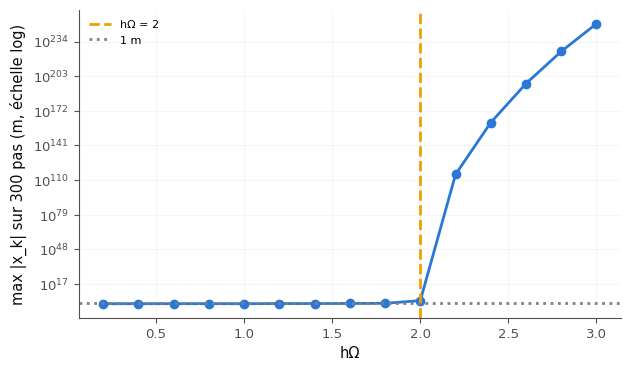

In [47]:
linear_recurrence = mymath.iterative.linear_recurrence


def leapfrog_28(h, n_terms):
    """x_0, ..., x_{n_terms − 1} of the leapfrog scheme of the oscillator, from x_0 = 0, x_1 = h v_0."""
    return linear_recurrence([2 - (h * OMEGA_28) ** 2, -1.0], [0.0, h * V0_28], n_terms)


amplitudes_28 = [float(np.max(np.abs(leapfrog_28(h, 301)))) for h in H_28]
answer_M19_28a = 2 / OMEGA_28
answer_M19_28b = max(h for h, a in zip(H_28, amplitudes_28) if a <= 1)
theta_28 = math.acos(1 - (0.03 * OMEGA_28) ** 2 / 2)
answer_M19_28c = 2 * math.pi / theta_28
answer_M19_28d = float(abs(leapfrog_28(answer_M19_28a, 1001)[1000]))
small_28 = leapfrog_28(0.03, 2001)
ups_28 = np.flatnonzero((small_28[:-1] < 0) & (small_28[1:] >= 0))      # the upward crossings of 0
print("amplitudes :", {h: f"{a:.3g}" for h, a in zip(H_28, amplitudes_28)})
print("a)", answer_M19_28a, " b)", answer_M19_28b, " c)", round(answer_M19_28c, 2), "; 2π/(hΩ) =",
      round(2 * math.pi / (0.03 * OMEGA_28), 2), "; mesurée sur 2 000 pas :", round(float(np.mean(np.diff(ups_28))), 2))
print("d)", round(answer_M19_28d, 1), "; |x_k| / k en h_c :", round(answer_M19_28d / 1000, 6))
fig_28, ax_28 = plt.subplots(figsize=(7.0, 4.0))
ax_28.semilogy([h * OMEGA_28 for h in H_28], amplitudes_28, "o-")
ax_28.axvline(2, color="C3", ls="--", label="hΩ = 2")
ax_28.axhline(1, color="0.5", ls=":", label="1 m")
ax_28.set_xlabel("hΩ")
ax_28.set_ylabel("max |x_k| sur 300 pas (m, échelle log)")
ax_28.legend(fontsize=8)
ax_28.grid(True, which="both", alpha=0.3)
plt.show()

In [48]:
omega_28r, v0_28r = 5.0, 1.5
h_c_28r = 2 / omega_28r
wbm.record("M19.28a", h_c_28r, decimals=6,
           mistakes={"|p| < 2 avec p = 2 − h²Ω² donne h²Ω² < 4 : prends la racine carrée": 4 / omega_28r ** 2,
                     "les racines restent complexes de module 1 tant que |2 − h²Ω²| < 2, pas |1 − h²Ω²| < 1":
                         math.sqrt(2) / omega_28r})


def amplitude_28r(h, n_terms=301):
    """max |x_k| of the leapfrog scheme, written again here (a plain loop)."""
    previous, current, largest = 0.0, h * v0_28r, h * v0_28r
    for _ in range(n_terms - 2):
        previous, current = current, (2 - (h * omega_28r) ** 2) * current - previous
        largest = max(largest, abs(current))
    return largest


grid_28r = [round(0.04 * k, 2) for k in range(1, 16)]
bounded_28r = max(h for h in grid_28r if amplitude_28r(h) <= 1)
assert bounded_28r < h_c_28r and amplitude_28r(h_c_28r) > 100
wbm.record("M19.28b", bounded_28r, decimals=6,
           mistakes={"en hΩ = 2, la racine double −1 fait grandir la suite comme k : elle n'est pas bornée": h_c_28r})
theta_28r = math.acos(1 - (0.03 * omega_28r) ** 2 / 2)
wbm.record("M19.28c", 2 * math.pi / theta_28r, decimals=2,
           mistakes={"la période du schéma est 2π/θ, avec cos θ = 1 − h²Ω²/2 : proche de 2π/(hΩ), sans lui être "
                     "égale": 2 * math.pi / (0.03 * omega_28r)})
x_28r = [0.0, h_c_28r * v0_28r]
while len(x_28r) <= 1000:
    x_28r.append(-2 * x_28r[-1] - x_28r[-2])                           # p = 2 − (h_c Ω)² = −2
wbm.record("M19.28d", abs(x_28r[1000]), decimals=6,
           mistakes={"x₁₀₀₀ est le terme d'indice 1 000 : il faut 1 001 termes": abs(x_28r[999])})

WBM_ANSWER {"coarse_any": {"1": ["c0ff3197d43c905df45e36994364037208b0f66765da388fce25d8898bf48c25"]}, "coarser": {"2": ["4f8d956070034f2b7815e03dab891e81621e938d5b78e6b06b12788fa128591e"], "3": ["e5aba1c64407ac63f0a5944887ba6e7e83da4a0962b00799370fd7fee3fee25a"], "4": ["3101e77782e52f15cb4270a9200f7150d63eb844cc1d4cb3fca5c016fc3daade"]}, "decimals": 6, "hash": "752e82f8db54305211a91fbe51451f911a610af284419195907d8d2d0e0cc04f", "hash_coarse": "30068f7b4f1370ce7221680f9519df78e8bd1ac99ca40a30415f73dc818a2c1b", "id": "M19.28a", "kind": "float", "magnitude": -1, "mistakes": {"4d0287b3600eec3c52e0d74f3a140a23e4f719cacb16fd304d7b2e696a940138": "|p| < 2 avec p = 2 − h²Ω² donne h²Ω² < 4 : prends la racine carrée", "a1b03925c3f9d8ff0908b6a65b3de2f5768b6f83c791cecef9ae0751e6a90374": "les racines restent complexes de module 1 tant que |2 − h²Ω²| < 2, pas |1 − h²Ω²| < 1"}, "sign": 1}
📝 Ex M19.28a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"1": ["aedcd7812a2408a13b9b8c2

**Dans ta copie**, réponds aux questions de l'énoncé, puis trace l'amplitude en fonction de $h\Omega$, en échelle logarithmique : que se passe-t-il de part et d'autre de $h\Omega = 2$ ?

💡 a) $h_c = \frac{2}{\Omega} = 0{,}4$ s. b) Jusqu'à $h = 0{,}36$ s ($h\Omega = 1{,}8$), l'amplitude reste bornée : $\frac{h\,v_0}{\sin\theta}$, soit 0,30 m pour les petits pas et $0{,}69$ m pour $0{,}36$ s ; elle grandit quand $h\Omega$ approche 2, car $\sin\theta \to 0$. En $h = 0{,}4$ s, la racine double $-1$ et le départ $(0, h\,v_0)$ donnent $x_k = -h\,v_0\,k\,(-1)^k$ : une croissance linéaire, $\lvert x_{300}\rvert = 180$ m ; au-delà, une racine réelle de module $> 1$ (produit 1) donne une croissance exponentielle, $10^{115}$ dès $h = 0{,}44$ s. c) $\cos\theta = 1 - 0{,}01125$, $\theta \approx 0{,}150141$ : $\frac{2\pi}{\theta} \approx 41{,}85$ pas, un peu moins que $\frac{2\pi}{h\Omega} \approx 41{,}89$ ; la simulation le confirme. d) $\lvert x_{1000}\rvert = 1\,000\,h_c\,v_0 = 600{,}0$ m. En $h\Omega = 0$, la racine double 1 donnerait aussi une croissance linéaire ($x_k = k\,x_1$) : c'est pourquoi l'intervalle est $0 < h\Omega < 2$. Les racines étant de module exactement 1, le schéma n'amortit pas l'oscillation, comme l'oscillateur exact. Pour une simulation fidèle, on garde un pas bien plus petit que $h_c$ (0,04 ou 0,08 s : l'amplitude reste à 1 % ou 2 % de 0,3 m), pas le plus grand pas borné.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu calculer une hessienne, à la main et par différences centrées, avec un pas bien choisi ?
2. Sais-tu classer un point critique de $\mathbb{R}^n$ par les signes des valeurs propres de sa hessienne ?
3. Sais-tu dire si une itération linéaire converge, et combien d'itérations elle demande ?
4. Sais-tu choisir le pas de Richardson, prévoir l'effet du conditionnement, et arrêter l'itération au bon moment ?
5. Sais-tu décider de la convergence d'une récurrence d'ordre 2 par le module de ses racines ?

**La suite** : le chapitre 19 de workbookIA, qui règle et compare des méthodes de descente par la courbure, puis M20 (tenseurs, axes et estimateurs pondérés), juste avant le chapitre 20 de workbookIA.